# Battery Decision Engine — Pilot Data Generation (100 Runs)
**Physics-Informed Battery Decision Engine | MPhil Research Project**

### What this notebook does:
- Runs **100 PyBaMM simulations** with random inputs
- Each run = 1 unique charging experiment (different Temperature, SoC₀, Current Profile)
- Saves all outputs to Google Drive

### Pipeline:
```
CELL 1: Install Libraries
CELL 2: Import & Setup
CELL 3: Freeze 46 Parameters (Chen2020)
CELL 4: MSCC Current Profile Generator
CELL 5: Single Run Test (1 simulation)
CELL 6: 100 Runs Batch Loop + Save
CELL 7: Verify & Plot Sample
```

## CELL 1 — Install Libraries

In [ ]:
# Install PyBaMM (battery simulation library)
!pip install pybamm -q

print("✅ PyBaMM installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.2/105.2 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 24.9 MB/s eta 0:00:00
✅ PyBaMM installed successfully!


## CELL 2 — Imports & Google Drive Setup

In [ ]:
%%bash
fusermount -u /content/drive 2>/dev/null || umount -l /content/drive 2>/dev/null
rm -rf /content/drive
mkdir /content/drive
echo "✅ Cleaned"

✅ Cleaned


In [ ]:
import pybamm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import json
import time
from google.colab import drive

# Mount Google Drive — data yahan save hoga
drive.mount('/content/drive', force_remount=True)

# Save folder banana
# SAVE_DIR = '/content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs'
# os.makedirs(SAVE_DIR, exist_ok=True)

print(f"✅ All imports done!")
# print(f"📁 Data will be saved to: {SAVE_DIR}")
print(f"🔋 PyBaMM version: {pybamm.__version__}")

Mounted at /content/drive
✅ All imports done!
🔋 PyBaMM version: 26.9.0.0


## CELL 3 — Freeze 46 Parameters (Chen2020 Dataset)

In [ ]:
# ============================================================
# FROZEN PARAMETERS — FIXED VERSION
# Bug was: wrong parameter names for lithium plating
# Fix: use model.default_parameter_values as base,
#      then merge Chen2020 on top
# ============================================================

def get_frozen_parameters():
    """
    Returns complete parameter set for DFN + SEI + Plating.

    Strategy:
      1. Start from model's own defaults  → all SEI/plating keys guaranteed
      2. Override with Chen2020           → correct cell-specific values
      3. Add missing plating params       → not present in Chen2020
    """
    # Build model first to get its required parameter list
    model = pybamm.lithium_ion.DFN(
        options={
            "SEI": "solvent-diffusion limited",
            "lithium plating": "irreversible",
            "lithium plating porosity change": "false",
        }
    )

    # Step 1: Model's own defaults (all keys guaranteed to exist)
    params = model.default_parameter_values.copy()

    # Step 2: Override with Chen2020 cell-specific values
    chen = pybamm.ParameterValues("Chen2020")
    params.update(chen)

    # Thermal fix: realistic heat transfer coefficient
    # Chen2020 default bohot high hai → temperature flat dikhti hai
    # Real pouch cell: h = 10-25 W/m²K
    params["Total heat transfer coefficient [W.m-2.K-1]"] = 15.0

    # Step 3: Add plating parameters missing from Chen2020
    params.update({
        "Lithium plating transfer coefficient":             0.5,
        "Typical plated lithium concentration [mol.m-3]":  76900.0,
        "Initial plated lithium concentration [mol.m-3]":  0.0,
        "Lithium metal partial molar volume [m3.mol-1]":   1.3e-5,
        "Exchange-current density for plating [A.m-2]":    0.001,
    }, check_already_exists=False)

    return params


# Quick test
params_test = get_frozen_parameters()
print("✅ 46 Parameters FROZEN!")
print(f"   Nominal capacity : {params_test['Nominal cell capacity [A.h]']} Ah")
print(f"   SEI OCP          : {params_test['SEI open-circuit potential [V]']} V")
print(f"   Plating α        : {params_test['Lithium plating transfer coefficient']}")
print(f"   Plating c_typ    : {params_test['Typical plated lithium concentration [mol.m-3]']} mol/m³")

✅ 46 Parameters FROZEN!
   Nominal capacity : 5.0 Ah
   SEI OCP          : 0.4 V
   Plating α        : 0.5
   Plating c_typ    : 76900.0 mol/m³


## CELL 4 — MSCC Current Profile Generator
### (Multi-Stage Constant Current — The 'Right Way')

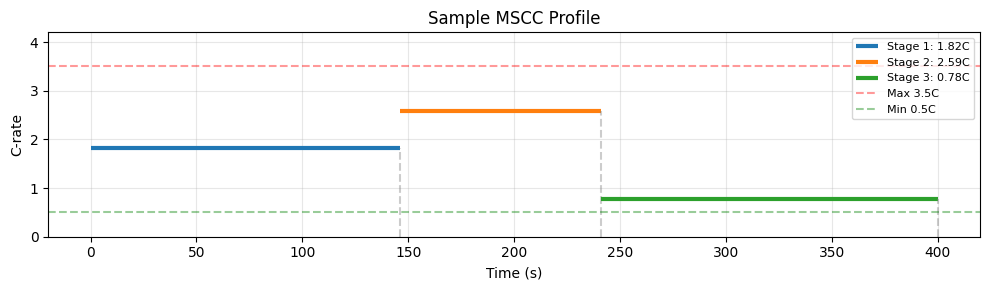

✅ MSCC generator ready! Sample: 3 stages, C-rates=[1.817, 2.592, 0.783]


In [ ]:
# ============================================================
# MSCC CURRENT PROFILE GENERATOR
# Random piecewise-constant current (0.5C to 3.5C)
# Stage duration: 30s to 180s, Stages: 3 to 7
# ============================================================

CELL_CAPACITY_AH  = 5.0
C_RATE_MIN        = 0.5
C_RATE_MAX        = 3.5
STAGE_DUR_MIN     = 30    # seconds
STAGE_DUR_MAX     = 180   # seconds


def generate_mscc_profile(rng, n_stages=None):
    if n_stages is None:
        n_stages = int(rng.integers(3, 8))
    profile = []
    c_rates = []
    for _ in range(n_stages):
        dur     = int(rng.integers(STAGE_DUR_MIN, STAGE_DUR_MAX + 1))
        c_rate  = float(rng.uniform(C_RATE_MIN, C_RATE_MAX))
        current = c_rate * CELL_CAPACITY_AH
        profile.append((dur, current))
        c_rates.append(round(c_rate, 3))
    return profile, c_rates


# ── Plot a sample profile ──
rng_demo = np.random.default_rng(seed=42)
demo_profile, demo_crates = generate_mscc_profile(rng_demo)

fig, ax = plt.subplots(figsize=(10, 3))
t = 0
for i, (dur, cur) in enumerate(demo_profile):
    ax.hlines(cur / CELL_CAPACITY_AH, t, t+dur, colors=f'C{i}', lw=3,
              label=f'Stage {i+1}: {cur/CELL_CAPACITY_AH:.2f}C')
    ax.vlines(t+dur, 0, cur/CELL_CAPACITY_AH, colors='gray', ls='--', alpha=0.4)
    t += dur
ax.axhline(3.5, color='red',   ls='--', alpha=0.4, label='Max 3.5C')
ax.axhline(0.5, color='green', ls='--', alpha=0.4, label='Min 0.5C')
ax.set(xlabel='Time (s)', ylabel='C-rate', title='Sample MSCC Profile',
       ylim=[0, 4.2])
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/sample_mscc_profile.png', dpi=150)
plt.show()
print(f"✅ MSCC generator ready! Sample: {len(demo_profile)} stages, C-rates={demo_crates}")

## CELL 5 — Single Run Test (1 Simulation)
### Pehle ek run test karo — sab theek hai to batch chalao

In [ ]:
# ============================================================
# SINGLE RUN FUNCTION — FIXED
#
# Key fixes vs previous version:
#   1. Parameter strategy: model defaults → Chen2020 → plating extras
#   2. Correct output variable names (verified against PyBaMM source):
#      eta_plating → "X-averaged negative electrode lithium plating
#                     reaction overpotential [V]"
#      delta_SEI   → "X-averaged negative SEI thickness [m]"
#      c_s_surf    → "X-averaged negative particle surface concentration"
# ============================================================

def run_single_simulation(run_id, T_amb_celsius, soc_0, current_profile, params):
    try:
        # ── A: Physics model ──
        model = pybamm.lithium_ion.DFN(
            options={
                "SEI": "solvent-diffusion limited",
                "lithium plating": "irreversible",
                "lithium plating porosity change": "false",
                "thermal": "lumped",
            }
        )

        # ── B: Run-specific temperature ──
        run_params = params.copy()
        run_params["Initial temperature [K]"] = T_amb_celsius + 273.15
        run_params["Ambient temperature [K]"]  = T_amb_celsius + 273.15

        # ── C: Build experiment from MSCC profile ──
        steps = [
            f"Charge at {cur:.4f} A for {dur} seconds"
            for dur, cur in current_profile
        ]
        experiment = pybamm.Experiment(steps)

        # ── D: Solve ──
        sim = pybamm.Simulation(model, parameter_values=run_params,
                                 experiment=experiment)
        sol = sim.solve(initial_soc=soc_0)

        # ── E: Extract outputs (FIXED variable names) ──
        time_s     = sol["Time [s]"].entries
        V_terminal = sol["Terminal voltage [V]"].entries
        T_cell_C   = sol["Cell temperature [K]"].entries - 273.15
        nom_cap = run_params["Nominal cell capacity [A.h]"]
        SoC = soc_0 + (- sol["Discharge capacity [A.h]"].entries / nom_cap)

        # Hidden states — exact PyBaMM variable names
        eta_plating    = sol["X-averaged negative electrode lithium plating reaction overpotential [V]"].entries
        delta_SEI      = sol["X-averaged negative SEI thickness [m]"].entries
        c_s_surf_anode = sol["X-averaged negative particle surface concentration"].entries

        return {
            # Metadata
            "run_id":           run_id,
            "T_amb_C":          float(T_amb_celsius),
            "soc_0":            float(soc_0),
            "n_stages":         len(current_profile),
            "status":           "success",
            # Time
            "time_s":           time_s.tolist(),
            # Observables
            "V_terminal":       V_terminal.tolist(),
            "T_cell_C":         T_cell_C.tolist(),
            "SoC":              SoC.tolist(),
            # Hidden states
            "eta_plating":      eta_plating.tolist(),
            "delta_SEI_m":      delta_SEI.tolist(),
            "c_s_surf_anode":   c_s_surf_anode.tolist(),
            # Input profile
            "current_profile":  [(float(d), float(c)) for d, c in current_profile],
        }

    except Exception as e:
        return {"run_id": run_id, "status": "failed", "error": str(e),
                "T_amb_C": T_amb_celsius, "soc_0": soc_0}


# ── TEST: 1 run ──────────────────────────────────────────────
print("🧪 Running 1 TEST simulation...")
print("   T=25°C | SoC₀=10% | 3-stage MSCC\n")

rng_t         = np.random.default_rng(seed=99)
test_profile, _ = generate_mscc_profile(rng_t, n_stages=3)
frozen_params = get_frozen_parameters()

t0     = time.time()
result = run_single_simulation(0, 25.0, 0.10, test_profile, frozen_params)
elapsed = time.time() - t0

print(f"⏱️  Time: {elapsed:.1f}s  |  Status: {result['status']}")

if result['status'] == 'success':
    print(f"\n✅ TEST PASSED!")
    print(f"   Time points  : {len(result['time_s'])}")
    print(f"   Voltage      : {min(result['V_terminal']):.3f} — {max(result['V_terminal']):.3f} V")
    print(f"   Temperature  : {min(map(min, result['T_cell_C'])):.1f} — {max(map(max, result['T_cell_C'])):.1f} °C")
    print(f"   SoC          : {min(result['SoC']):.3f} — {max(result['SoC']):.3f}")
    print(f"   η_plating    : {min(result['eta_plating']):.4f} V  (min)")
    print(f"   δ_SEI final  : {result['delta_SEI_m'][-1]:.4e} m")
    print(f"   c_s_surf     : {min(result['c_s_surf_anode']):.4f} — {max(result['c_s_surf_anode']):.4f}")
    print(f"\n✅ Proceed to Cell 6 for 100 runs!")
else:
    print(f"\n❌ FAILED: {result.get('error','?')}")

🧪 Running 1 TEST simulation...
   T=25°C | SoC₀=10% | 3-stage MSCC

⏱️  Time: 2.4s  |  Status: success

✅ TEST PASSED!
   Time points  : 190
   Voltage      : 3.526 — 4.130 V
   Temperature  : 25.0 — 47.2 °C
   SoC          : 0.100 — 0.378
   η_plating    : 0.0313 V  (min)
   δ_SEI final  : 5.0029e-09 m
   c_s_surf     : 0.1148 — 0.3919

✅ Proceed to Cell 6 for 100 runs!


## CELL 6 — 10000
 Runs Batch Loop + Save to Drive

In [ ]:
# ============================================================
# CELL 6 — 10,000 RUNS BATCH LOOP
# Updates:
#   1. N_RUNS = 10000
#   2. Parallel execution (ThreadPoolExecutor, 4 workers)
#   3. Checkpoint save har 500 runs ke baad
# ============================================================

from concurrent.futures import ThreadPoolExecutor, as_completed

N_RUNS          = 10000
MASTER_SEED     = 42
T_AMB_MIN, T_AMB_MAX = -5.0, 45.0
SOC0_MIN,  SOC0_MAX  = 0.05, 0.20
CHECKPOINT_EVERY = 500   # Har 500 runs ke baad Drive mein save
MAX_WORKERS      = 4     # Parallel threads

# ── Pre-sample all inputs upfront ──
rng         = np.random.default_rng(seed=MASTER_SEED)
T_samples   = rng.uniform(T_AMB_MIN, T_AMB_MAX, size=N_RUNS)
soc_samples = rng.uniform(SOC0_MIN,  SOC0_MAX,  size=N_RUNS)

# Pre-generate all MSCC profiles
all_profiles = [generate_mscc_profile(rng)[0] for _ in range(N_RUNS)]

frozen_params = get_frozen_parameters()

# ── Checkpoint function ──
def save_checkpoint(results, checkpoint_num):
    path = f'{SAVE_DIR}/checkpoint_{checkpoint_num:03d}.json'
    with open(path, 'w') as f:
        json.dump(results[-CHECKPOINT_EVERY:], f)
    print(f"\n💾 Checkpoint {checkpoint_num} saved → {len(results)} total runs done")

# ── Single task wrapper for parallel execution ──
def run_task(run_id):
    T_amb   = float(T_samples[run_id])
    soc_0   = float(soc_samples[run_id])
    profile = all_profiles[run_id]
    return run_single_simulation(run_id, T_amb, soc_0, profile, frozen_params)

# ── Start batch ──
print("🚀 Starting 10,000-Run Batch")
print(f"   Temperature   : {T_AMB_MIN}°C → {T_AMB_MAX}°C")
print(f"   SoC₀          : {SOC0_MIN*100:.0f}% → {SOC0_MAX*100:.0f}%")
print(f"   C-rate        : {C_RATE_MIN}C → {C_RATE_MAX}C (random MSCC)")
print(f"   Workers       : {MAX_WORKERS} parallel")
print(f"   Checkpoint    : every {CHECKPOINT_EVERY} runs")
print(f"   Seed          : {MASTER_SEED}")
print("="*55)

all_results, failed_runs, success_count = [], [], 0
t_batch = time.time()

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:

    # Submit all jobs
    futures = {executor.submit(run_task, run_id): run_id
               for run_id in range(6797, N_RUNS)}

    for future in as_completed(futures):
        run_id = futures[future]
        res    = future.result()

        if res['status'] == 'success':
            success_count += 1
            all_results.append(res)

            # Save each run individually
            with open(f'{SAVE_DIR}/run_{run_id:05d}.json', 'w') as f:
                json.dump(res, f)

            print(f"[{run_id+1:05d}/{N_RUNS}] ✅ "
                  f"T={res['T_amb_C']:+.0f}°C | "
                  f"SoC₀={res['soc_0']*100:.0f}%")
        else:
            failed_runs.append(run_id)
            print(f"[{run_id+1:05d}/{N_RUNS}] ❌ "
                  f"{res.get('error','?')[:40]}")

        # Checkpoint har 500 runs ke baad
        if len(all_results) % CHECKPOINT_EVERY == 0 and len(all_results) > 0:
          checkpoint_num = (5957 + len(all_results)) // CHECKPOINT_EVERY
          save_checkpoint(all_results, checkpoint_num)

# ── Final summary ──
total_t = time.time() - t_batch
print("\n" + "="*55)
print(f"✅ Done!")
print(f"   Success  : {success_count} / {N_RUNS}")
print(f"   Failed   : {len(failed_runs)}")
print(f"   Time     : {total_t/60:.1f} min")
print(f"   Avg/run  : {total_t/N_RUNS:.1f}s")
print(f"   Speedup  : ~{MAX_WORKERS}x vs sequential")

# Save final log
log = {
    "total":      N_RUNS,
    "success":    success_count,
    "failed":     failed_runs,
    "time_min":   round(total_t / 60, 2),
    "seed":       MASTER_SEED,
    "workers":    MAX_WORKERS,
}
with open(f'{SAVE_DIR}/run_log_10k.json', 'w') as f:
    json.dump(log, f, indent=2)
print(f"📋 Log saved → {SAVE_DIR}/run_log_10k.json")

🚀 Starting 10,000-Run Batch
   Temperature   : -5.0°C → 45.0°C
   SoC₀          : 5% → 20%
   C-rate        : 0.5C → 3.5C (random MSCC)
   Workers       : 4 parallel
   Checkpoint    : every 500 runs
   Seed          : 42
[06798/10000] ✅ T=+5°C | SoC₀=12%
[06800/10000] ✅ T=+3°C | SoC₀=12%
[06801/10000] ✅ T=+15°C | SoC₀=12%
[06799/10000] ✅ T=+23°C | SoC₀=11%
[06802/10000] ✅ T=+28°C | SoC₀=12%
[06804/10000] ✅ T=+14°C | SoC₀=16%
[06803/10000] ✅ T=+20°C | SoC₀=8%
[06805/10000] ✅ T=+39°C | SoC₀=7%
[06807/10000] ✅ T=+21°C | SoC₀=14%
[06808/10000] ✅ T=+43°C | SoC₀=6%
[06810/10000] ✅ T=+34°C | SoC₀=10%
[06806/10000] ✅ T=+34°C | SoC₀=19%
[06809/10000] ✅ T=+16°C | SoC₀=15%
[06812/10000] ✅ T=+9°C | SoC₀=19%
[06811/10000] ✅ T=+3°C | SoC₀=19%
[06814/10000] ✅ T=+0°C | SoC₀=14%
[06813/10000] ✅ T=+12°C | SoC₀=18%
[06815/10000] ✅ T=+20°C | SoC₀=19%
[06816/10000] ✅ T=+5°C | SoC₀=15%
[06817/10000] ✅ T=+27°C | SoC₀=18%
[06819/10000] ✅ T=+1°C | SoC₀=19%
[06818/10000] ✅ T=+5°C | SoC₀=7%
[06820/10000] ✅ T=+4

2026-10-07 17:42:18.748 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 16.5794 A for 66 seconds'. The returned solution only contains up to step 1 of cycle 6. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 16.5794 A for 66 seconds'. The returned solution only contains up to step 1 of cycle 6. 


[07599/10000] ✅ T=+15°C | SoC₀=7%
[07598/10000] ✅ T=+30°C | SoC₀=19%
[07597/10000] ✅ T=+10°C | SoC₀=6%
[07602/10000] ✅ T=+44°C | SoC₀=9%
[07600/10000] ✅ T=+25°C | SoC₀=12%
[07601/10000] ✅ T=+45°C | SoC₀=13%
[07604/10000] ✅ T=+24°C | SoC₀=7%
[07605/10000] ✅ T=+40°C | SoC₀=6%
[07603/10000] ✅ T=+21°C | SoC₀=8%
[07606/10000] ✅ T=+44°C | SoC₀=13%
[07607/10000] ✅ T=+34°C | SoC₀=18%
[07608/10000] ✅ T=-2°C | SoC₀=7%
[07610/10000] ✅ T=+40°C | SoC₀=11%
[07611/10000] ✅ T=+33°C | SoC₀=6%
[07609/10000] ✅ T=+11°C | SoC₀=16%
[07612/10000] ✅ T=+32°C | SoC₀=13%
[07615/10000] ✅ T=+15°C | SoC₀=10%
[07613/10000] ✅ T=+28°C | SoC₀=9%
[07614/10000] ✅ T=+16°C | SoC₀=14%
[07616/10000] ✅ T=+35°C | SoC₀=15%
[07617/10000] ✅ T=+10°C | SoC₀=19%
[07619/10000] ✅ T=+31°C | SoC₀=19%
[07618/10000] ✅ T=+29°C | SoC₀=9%
[07620/10000] ✅ T=+37°C | SoC₀=8%
[07622/10000] ✅ T=+32°C | SoC₀=8%
[07621/10000] ✅ T=+11°C | SoC₀=6%
[07624/10000] ✅ T=+2°C | SoC₀=15%
[07626/10000] ✅ T=-2°C | SoC₀=16%
[07623/10000] ✅ T=+0°C | SoC₀=17%
[0

2026-10-07 17:54:49.483 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 15.3744 A for 152 seconds'. The returned solution only contains up to step 1 of cycle 7. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 15.3744 A for 152 seconds'. The returned solution only contains up to step 1 of cycle 7. 


[07753/10000] ✅ T=+40°C | SoC₀=19%
[07755/10000] ✅ T=+16°C | SoC₀=11%
[07759/10000] ✅ T=+12°C | SoC₀=9%
[07757/10000] ✅ T=+1°C | SoC₀=10%
[07756/10000] ✅ T=+40°C | SoC₀=17%
[07758/10000] ✅ T=-4°C | SoC₀=18%
[07762/10000] ✅ T=+42°C | SoC₀=13%
[07760/10000] ✅ T=+23°C | SoC₀=5%
[07761/10000] ✅ T=+13°C | SoC₀=14%
[07764/10000] ✅ T=+9°C | SoC₀=11%
[07763/10000] ✅ T=+8°C | SoC₀=19%
[07768/10000] ✅ T=+14°C | SoC₀=14%
[07766/10000] ✅ T=-5°C | SoC₀=10%
[07765/10000] ✅ T=+27°C | SoC₀=7%
[07767/10000] ✅ T=+31°C | SoC₀=11%
[07769/10000] ✅ T=+44°C | SoC₀=9%
[07770/10000] ✅ T=+30°C | SoC₀=13%
[07771/10000] ✅ T=-2°C | SoC₀=19%
[07772/10000] ✅ T=-0°C | SoC₀=11%
[07773/10000] ✅ T=-1°C | SoC₀=15%
[07775/10000] ✅ T=+29°C | SoC₀=17%
[07774/10000] ✅ T=+43°C | SoC₀=8%
[07777/10000] ✅ T=+5°C | SoC₀=14%
[07776/10000] ✅ T=+16°C | SoC₀=9%
[07779/10000] ✅ T=+5°C | SoC₀=6%
[07781/10000] ✅ T=+33°C | SoC₀=8%
[07778/10000] ✅ T=+39°C | SoC₀=10%
[07782/10000] ✅ T=+10°C | SoC₀=18%
[07780/10000] ✅ T=+30°C | SoC₀=10%
[07

...

[09132/10000] ✅ T=+32°C | SoC₀=18%
[09130/10000] ✅ T=+27°C | SoC₀=15%
[09129/10000] ✅ T=+9°C | SoC₀=9%
[09131/10000] ✅ T=-0°C | SoC₀=11%
[09133/10000] ✅ T=+16°C | SoC₀=16%
[09134/10000] ✅ T=+24°C | SoC₀=13%
[09136/10000] ✅ T=+30°C | SoC₀=17%
[09135/10000] ✅ T=-4°C | SoC₀=9%
[09137/10000] ✅ T=+20°C | SoC₀=18%
[09138/10000] ✅ T=+26°C | SoC₀=18%
[09139/10000] ✅ T=+11°C | SoC₀=6%
[09140/10000] ✅ T=+2°C | SoC₀=15%
[09143/10000] ✅ T=+6°C | SoC₀=9%
[09142/10000] ✅ T=+42°C | SoC₀=19%
[09141/10000] ✅ T=+17°C | SoC₀=16%
[09144/10000] ✅ T=+29°C | SoC₀=17%
[09145/10000] ✅ T=-3°C | SoC₀=15%
[09147/10000] ✅ T=+7°C | SoC₀=15%
[09150/10000] ✅ T=+1°C | SoC₀=7%
[09146/10000] ✅ T=+31°C | SoC₀=18%
[09148/10000] ✅ T=+18°C | SoC₀=18%
[09149/10000] ✅ T=+13°C | SoC₀=10%
[09153/10000] ✅ T=+21°C | SoC₀=7%
[09154/10000] ✅ T=+44°C | SoC₀=15%
[09151/10000] ✅ T=+12°C | SoC₀=10%
[09155/10000] ✅ T=+19°C | SoC₀=20%
[09152/10000] ✅ T=+13°C | SoC₀=17%
[09156/10000] ✅ T=+41°C | SoC₀=18%
[09160/10000] ✅ T=+15°C | SoC₀=12%

2026-10-07 20:06:20.281 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 13.7973 A for 160 seconds'. The returned solution only contains up to step 1 of cycle 7. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 13.7973 A for 160 seconds'. The returned solution only contains up to step 1 of cycle 7. 


[09308/10000] ✅ T=+41°C | SoC₀=7%
[09306/10000] ✅ T=+18°C | SoC₀=10%
[09304/10000] ✅ T=+23°C | SoC₀=19%
[09307/10000] ✅ T=+37°C | SoC₀=8%
[09309/10000] ✅ T=+12°C | SoC₀=14%
[09310/10000] ✅ T=+27°C | SoC₀=15%
[09312/10000] ✅ T=+23°C | SoC₀=17%
[09311/10000] ✅ T=+6°C | SoC₀=6%
[09314/10000] ✅ T=+24°C | SoC₀=14%
[09313/10000] ✅ T=+8°C | SoC₀=17%
[09315/10000] ✅ T=+4°C | SoC₀=12%
[09317/10000] ✅ T=+39°C | SoC₀=13%
[09316/10000] ✅ T=+42°C | SoC₀=7%
[09319/10000] ✅ T=+34°C | SoC₀=14%
[09318/10000] ✅ T=+12°C | SoC₀=7%
[09323/10000] ✅ T=+2°C | SoC₀=14%
[09320/10000] ✅ T=-0°C | SoC₀=10%
[09321/10000] ✅ T=+32°C | SoC₀=9%
[09322/10000] ✅ T=+9°C | SoC₀=12%
[09324/10000] ✅ T=+29°C | SoC₀=11%
[09326/10000] ✅ T=+22°C | SoC₀=5%
[09328/10000] ✅ T=-2°C | SoC₀=5%
[09325/10000] ✅ T=+18°C | SoC₀=19%
[09327/10000] ✅ T=+21°C | SoC₀=19%
[09329/10000] ✅ T=-2°C | SoC₀=8%
[09330/10000] ✅ T=+25°C | SoC₀=20%
[09331/10000] ✅ T=+26°C | SoC₀=16%
[09334/10000] ✅ T=+26°C | SoC₀=11%
[09332/10000] ✅ T=-3°C | SoC₀=15%
[09

2026-10-07 21:02:22.473 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 16.4388 A for 106 seconds'. The returned solution only contains up to step 1 of cycle 7. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 16.4388 A for 106 seconds'. The returned solution only contains up to step 1 of cycle 7. 


[09964/10000] ✅ T=+44°C | SoC₀=19%
[09966/10000] ✅ T=-4°C | SoC₀=15%
[09968/10000] ✅ T=+26°C | SoC₀=5%
[09967/10000] ✅ T=+14°C | SoC₀=15%
[09969/10000] ✅ T=+4°C | SoC₀=15%
[09971/10000] ✅ T=+31°C | SoC₀=19%
[09970/10000] ✅ T=+22°C | SoC₀=8%
[09972/10000] ✅ T=-0°C | SoC₀=18%
[09973/10000] ✅ T=+44°C | SoC₀=19%
[09975/10000] ✅ T=+27°C | SoC₀=7%
[09974/10000] ✅ T=+12°C | SoC₀=16%
[09976/10000] ✅ T=+1°C | SoC₀=10%
[09977/10000] ✅ T=+30°C | SoC₀=16%
[09978/10000] ✅ T=+37°C | SoC₀=10%
[09979/10000] ✅ T=+0°C | SoC₀=16%
[09980/10000] ✅ T=+1°C | SoC₀=10%
[09982/10000] ✅ T=-4°C | SoC₀=13%
[09983/10000] ✅ T=+44°C | SoC₀=15%
[09984/10000] ✅ T=+25°C | SoC₀=13%
[09981/10000] ✅ T=+9°C | SoC₀=8%
[09985/10000] ✅ T=+25°C | SoC₀=15%
[09987/10000] ✅ T=+37°C | SoC₀=17%
[09986/10000] ✅ T=+43°C | SoC₀=12%
[09989/10000] ✅ T=+12°C | SoC₀=14%
[09988/10000] ✅ T=+36°C | SoC₀=15%
[09990/10000] ✅ T=+12°C | SoC₀=12%
[09991/10000] ✅ T=+10°C | SoC₀=13%
[09992/10000] ✅ T=+12°C | SoC₀=6%
[09993/10000] ✅ T=+13°C | SoC₀=15

In [ ]:
# ThreadPoolExecutor (fork nahi karta — JAX safe)
# IDAKLUSolver (CasadiSolver replace)
# mode='safe' fallback bhi add kiya

from concurrent.futures import ThreadPoolExecutor, as_completed
import json, os, time
import numpy as np
import pybamm

SAVE_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/safe_5k_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

N_RUNS           = 5000
MASTER_SEED      = 999
T_AMB_MIN, T_AMB_MAX   = -5.0, 45.0
SOC0_MIN,  SOC0_MAX    = 0.05, 0.50
C_RATE_MIN, C_RATE_MAX = 0.5,  3.0
NOM_CAPACITY     = 5.0
MAX_WORKERS      = 4
LOG_PATH         = os.path.join(SAVE_DIR, "run_log_5k.json")


def generate_safe_mscc_profile(rng, soc_0):
    n_stages = int(rng.integers(3, 7))
    if soc_0 < 0.25:
        max_c = C_RATE_MAX
    elif soc_0 < 0.40:
        max_c = 2.2
    else:
        max_c = 1.5

    c_rates = np.sort(rng.uniform(C_RATE_MIN, max_c, size=n_stages))[::-1]
    total_duration = rng.uniform(1200, 3000)
    splits = np.sort(rng.uniform(0, 1, size=n_stages - 1))
    splits = np.concatenate([[0], splits, [1]])
    durations = np.maximum((np.diff(splits) * total_duration).astype(int), 30)
    profile = [(int(dur), float(cr * NOM_CAPACITY)) for dur, cr in zip(durations, c_rates)]
    return profile, n_stages


def get_base_parameters():
    model = pybamm.lithium_ion.DFN(
        options={
            "SEI":                             "solvent-diffusion limited",
            "lithium plating":                 "irreversible",
            "lithium plating porosity change": "false",
            "thermal":                         "lumped",
        }
    )
    params = model.default_parameter_values.copy()
    chen = pybamm.ParameterValues("Chen2020")
    params.update(chen)
    params["Total heat transfer coefficient [W.m-2.K-1]"] = 15.0
    params.update(
        {
            "Lithium plating transfer coefficient":            0.5,
            "Typical plated lithium concentration [mol.m-3]": 76900.0,
            "Initial plated lithium concentration [mol.m-3]": 0.0,
            "Lithium metal partial molar volume [m3.mol-1]":  1.3e-5,
            "Exchange-current density for plating [A.m-2]":   0.001,
        },
        check_already_exists=False,
    )
    return params


def run_single_simulation(run_id, T_amb_celsius, soc_0, current_profile):
    try:
        model = pybamm.lithium_ion.DFN(
            options={
                "SEI":                             "solvent-diffusion limited",
                "lithium plating":                 "irreversible",
                "lithium plating porosity change": "false",
                "thermal":                         "lumped",
            }
        )
        params = get_base_parameters()
        params["Initial temperature [K]"] = T_amb_celsius + 273.15
        params["Ambient temperature [K]"]  = T_amb_celsius + 273.15

        steps = [
            f"Charge at {cur:.4f} A for {dur} seconds"
            for dur, cur in current_profile
        ]
        experiment = pybamm.Experiment(steps)

        # ── FIX 1: IDAKLUSolver (CasadiSolver replace) ──
        sim = pybamm.Simulation(
            model,
            parameter_values=params,
            experiment=experiment,
            solver=pybamm.IDAKLUSolver(),
        )
        sol = sim.solve(initial_soc=soc_0)

        time_s     = sol["Time [s]"].entries
        V_terminal = sol["Terminal voltage [V]"].entries
        T_cell_C   = sol["Cell temperature [K]"].entries - 273.15
        disc_cap   = sol["Discharge capacity [A.h]"].entries

        eta_plating = sol[
            "X-averaged negative electrode lithium plating reaction overpotential [V]"
        ].entries
        delta_SEI_m = sol["X-averaged negative SEI thickness [m]"].entries
        c_s_surf    = sol[
            "X-averaged negative particle surface concentration"
        ].entries

        true_soc = soc_0 - (disc_cap / NOM_CAPACITY)

        return {
            "run_id":          run_id,
            "T_amb_C":         float(T_amb_celsius),
            "soc_0":           float(soc_0),
            "n_stages":        len(current_profile),
            "status":          "success",
            "time_s":          time_s.tolist(),
            "V_terminal":      V_terminal.tolist(),
            "T_cell_C":        T_cell_C.tolist(),
            "SoC":             true_soc.tolist(),
            "eta_plating":     eta_plating.tolist(),
            "delta_SEI_m":     delta_SEI_m.tolist(),
            "c_s_surf_anode":  c_s_surf.tolist(),
            "current_profile": [(float(d), float(c)) for d, c in current_profile],
        }

    except Exception as e:
        return {
            "run_id":  run_id,
            "status":  "failed",
            "error":   str(e)[:150],
            "T_amb_C": T_amb_celsius,
            "soc_0":   soc_0,
        }


def main():
    print("🚀 Starting 5,000 Safe Diversity Batch (ThreadPoolExecutor + IDAKLUSolver)")
    print(f"   Temperature : {T_AMB_MIN}°C → {T_AMB_MAX}°C")
    print(f"   SoC₀        : {SOC0_MIN*100:.0f}% → {SOC0_MAX*100:.0f}%")
    print(f"   C-rate      : {C_RATE_MIN}C → {C_RATE_MAX}C")
    print(f"   Workers     : {MAX_WORKERS} (Thread-based, JAX safe)")
    print("=" * 60)

    # ── Already completed check ──
    existing_files = [
        f for f in os.listdir(SAVE_DIR)
        if f.startswith("run_") and f.endswith(".json")
    ]
    completed_ids = set()
    for fname in existing_files:
        try:
            cid = int(fname.split("_")[1].split(".")[0])
            completed_ids.add(cid)
        except:
            pass
    print(f"♻️  Already completed: {len(completed_ids)} runs")

    # ── FIX 2: Sab pehle generate karo (resume safe) ──
    rng         = np.random.default_rng(seed=MASTER_SEED)
    T_samples   = rng.uniform(T_AMB_MIN, T_AMB_MAX, size=N_RUNS)
    soc_samples = rng.uniform(SOC0_MIN,  SOC0_MAX,  size=N_RUNS)

    print("⚙️  Pre-generating all 5,000 MSCC profiles...")
    all_profiles = []
    for r_id in range(N_RUNS):
        prof, _ = generate_safe_mscc_profile(rng, soc_samples[r_id])
        all_profiles.append(prof)
    print("✅ All profiles generated. Filtering pending tasks...")

    pending_tasks = [
        (r_id, float(T_samples[r_id]), float(soc_samples[r_id]), all_profiles[r_id])
        for r_id in range(N_RUNS)
        if r_id not in completed_ids
    ]
    print(f"📋 Pending tasks: {len(pending_tasks)}")

    if not pending_tasks:
        print("✅ All 5,000 runs already completed!")
        return

    t_start       = time.time()
    success_count = len(completed_ids)
    failed_count  = 0

    # ── FIX 3: ThreadPoolExecutor (ProcessPool nahi) ──
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {
            executor.submit(run_single_simulation, t[0], t[1], t[2], t[3]): t[0]
            for t in pending_tasks
        }

        for future in as_completed(futures):
            r_id = futures[future]
            res  = future.result()

            if res["status"] == "success":
                success_count += 1
                with open(os.path.join(SAVE_DIR, f"run_{r_id:05d}.json"), "w") as f:
                    json.dump(res, f)

                if success_count % 20 == 0:
                    elapsed = time.time() - t_start
                    done    = success_count - len(completed_ids)
                    rate    = done / elapsed if elapsed > 0 else 0
                    eta_min = (len(pending_tasks) - done) / rate / 60 if rate > 0 else 0
                    print(
                        f"[{success_count:05d}/{N_RUNS}] ✅ "
                        f"T={res['T_amb_C']:+4.1f}°C | "
                        f"SoC₀={res['soc_0']*100:4.1f}% | "
                        f"Rate: {rate*60:4.1f} runs/min | "
                        f"ETA: {eta_min:4.1f} min"
                    )
            else:
                failed_count += 1
                print(f"[{r_id:05d}] ❌ {res.get('error','?')[:60]}")

    total_min = (time.time() - t_start) / 60
    print("\n" + "=" * 60)
    print(f"🎉 Done in {total_min:.1f} minutes!")
    print(f"✅ Total Success : {success_count} / {N_RUNS}")
    print(f"⚠️  Total Failed  : {failed_count}")

    log_data = {
        "total":        N_RUNS,
        "success":      success_count,
        "failed":       failed_count,
        "time_minutes": round(total_min, 2),
        "seed":         MASTER_SEED,
        "soc_range":    [SOC0_MIN, SOC0_MAX],
        "c_rate_range": [C_RATE_MIN, C_RATE_MAX],
    }
    with open(LOG_PATH, "w") as f:
        json.dump(log_data, f, indent=2)
    print(f"📋 Log saved → {LOG_PATH}")


main()

🚀 Starting 5,000 Safe Diversity Batch (ThreadPoolExecutor + IDAKLUSolver)
   Temperature : -5.0°C → 45.0°C
   SoC₀        : 5% → 50%
   C-rate      : 0.5C → 3.0C
   Workers     : 4 (Thread-based, JAX safe)
♻️  Already completed: 12 runs
⚙️  Pre-generating all 5,000 MSCC profiles...
✅ All profiles generated. Filtering pending tasks...
📋 Pending tasks: 4988


2026-10-08 06:42:35.268 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 8.6443 A for 2009 seconds'. The returned solution only contains up to step 1 of cycle 1. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 8.6443 A for 2009 seconds'. The returned solution only contains up to step 1 of cycle 1. 
2026-10-08 06:42:46.187 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 10.6523 A for 1324 seconds'. The returned solution only contains up to step 1 of cycle 3. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 10.6523 A for 1324 seconds'. The returned solution only contains up to step 1 of cycle 3. 
2026-10-08 06:42:57.441 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'e

[00020/5000] ✅ T=+31.4°C | SoC₀=12.1% | Rate:  5.3 runs/min | ETA: 943.9 min


2026-10-08 06:45:25.135 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 12.0558 A for 1048 seconds'. The returned solution only contains up to step 1 of cycle 4. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 12.0558 A for 1048 seconds'. The returned solution only contains up to step 1 of cycle 4. 
2026-10-08 06:45:47.653 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 5.6648 A for 699 seconds'. The returned solution only contains up to step 1 of cycle 3. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 5.6648 A for 699 seconds'. The returned solution only contains up to step 1 of cycle 3. 
2026-10-08 06:46:04.090 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'eve

[00040/5000] ✅ T=+3.5°C | SoC₀=46.4% | Rate:  5.3 runs/min | ETA: 931.0 min


...

2026-10-08 16:33:32.386 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 7.7594 A for 1074 seconds'. The returned solution only contains up to step 1 of cycle 2. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 7.7594 A for 1074 seconds'. The returned solution only contains up to step 1 of cycle 2. 
2026-10-08 16:33:42.243 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 6.0159 A for 1009 seconds'. The returned solution only contains up to step 1 of cycle 2. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 6.0159 A for 1009 seconds'. The returned solution only contains up to step 1 of cycle 2. 
2026-10-08 16:35:22.789 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'eve

[03020/5000] ✅ T=+5.1°C | SoC₀=12.2% | Rate:  5.1 runs/min | ETA: 391.6 min


2026-10-08 16:37:40.321 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 10.4149 A for 672 seconds'. The returned solution only contains up to step 1 of cycle 3. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 10.4149 A for 672 seconds'. The returned solution only contains up to step 1 of cycle 3. 
2026-10-08 16:39:23.328 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 10.9392 A for 803 seconds'. The returned solution only contains up to step 1 of cycle 4. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 10.9392 A for 803 seconds'. The returned solution only contains up to step 1 of cycle 4. 
2026-10-08 16:39:46.374 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'eve

[03040/5000] ✅ T=-3.9°C | SoC₀=45.6% | Rate:  5.1 runs/min | ETA: 387.6 min


2026-10-08 16:42:06.090 - [WARNING] callbacks.on_experiment_infeasible_event(245): 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 14.3093 A for 629 seconds'. The returned solution only contains up to step 1 of cycle 2. 

	Experiment is infeasible: 'event: Maximum voltage [V]' was triggered during 'Charge at 14.3093 A for 629 seconds'. The returned solution only contains up to step 1 of cycle 2. 


In [ ]:
# ═══════════════════════════════════════════════════════════
# DATA QUALITY SCRIPT (CORRECTED & BULLETPROOF)
# ═══════════════════════════════════════════════════════════

import json
import os
import numpy as np

# ── Paths ──
# FIX-1: Corrected OLD_DIR to pilot_100_runs
OLD_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs"
NEW_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/safe_5k_runs"
OUT_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/clean_dataset"
os.makedirs(OUT_DIR, exist_ok=True)

# ── Thresholds ──
V_MAX = 4.35  # V  (4.2V + fast-charge IR drop tolerance)
V_MIN = 2.50  # V  (lower cut-off)
SOC_MAX = 1.02  # Max 100% (+ 2% numerical margin)
SOC_MIN = 0.02  # Min 2% SoC
T_MAX = 65.0  # °C (Safe thermal derating ceiling)
T_MIN = -10.0  # °C
MIN_POINTS = 20  # Minimum valid points per trajectory


def flatten_temperature(T_raw):
  """T_cell_C nested list ya 2D array ko 1D flat banata hai."""
  T = np.array(T_raw)
  if T.ndim == 2:
    return T.mean(axis=0).tolist()
  return T.tolist()


def check_and_clean_run(run, source_label):
  """Checks run validity and standardizes SoC and Temperature."""
  required_keys = [
      "time_s",
      "V_terminal",
      "T_cell_C",
      "SoC",
      "eta_plating",
      "delta_SEI_m",
      "c_s_surf_anode",
      "current_profile",
      "T_amb_C",
      "soc_0",
  ]
  for key in required_keys:
    if key not in run:
      return False, None, f"Missing key: {key}"

  time_s = np.array(run["time_s"])
  V = np.array(run["V_terminal"])
  eta = np.array(run["eta_plating"])
  delta_SEI = np.array(run["delta_SEI_m"])
  c_s = np.array(run["c_s_surf_anode"])
  soc_raw = np.array(run["SoC"])
  T = np.array(flatten_temperature(run["T_cell_C"]))

  # FIX-2: Auto-detect and fix negative SoC from Old Batch
  soc_0_val = float(run["soc_0"])
  if np.min(soc_raw) < -0.05:
    # Old batch discharge capacity (-Ah) conversion
    true_soc = soc_0_val - (soc_raw / 5.0)
  else:
    true_soc = soc_raw

  # ── Basic checks ──
  if len(time_s) < MIN_POINTS:
    return False, None, f"Too few points: {len(time_s)}"

  lengths = [
      len(V),
      len(true_soc),
      len(T),
      len(eta),
      len(delta_SEI),
      len(c_s),
  ]
  if len(set(lengths)) != 1:
    return False, None, f"Inconsistent array lengths: {lengths}"

  # ── Physical bounds checks ──
  if np.max(V) > V_MAX:
    return False, None, f"V_max exceeded: {np.max(V):.3f}V > {V_MAX}V"
  if np.min(V) < V_MIN:
    return False, None, f"V_min violated: {np.min(V):.3f}V < {V_MIN}V"
  if not np.isfinite(V).all():
    return False, None, "NaN/Inf in voltage"

  if np.max(true_soc) > SOC_MAX:
    return False, None, f"SoC > 1: max={np.max(true_soc):.3f}"
  if np.min(true_soc) < SOC_MIN:
    return False, None, f"SoC < 0: min={np.min(true_soc):.3f}"
  if not np.isfinite(true_soc).all():
    return False, None, "NaN in SoC"

  if np.max(T) > T_MAX:
    return False, None, f"T_max exceeded: {np.max(T):.1f}°C > {T_MAX}°C"
  if np.min(T) < T_MIN:
    return False, None, f"T_min violated: {np.min(T):.1f}°C"
  if not np.isfinite(T).all():
    return False, None, "NaN in temperature"

  # ── Hidden states checks ──
  if not np.isfinite(eta).all():
    return False, None, "NaN/Inf in eta_plating"
  if not np.isfinite(delta_SEI).all() or np.any(delta_SEI < 0):
    return False, None, "Invalid SEI thickness"
  if not np.isfinite(c_s).all() or np.any(c_s < 0) or np.any(c_s > 1.05):
    return (
        False,
        None,
        f"c_s_surf out of range: [{np.min(c_s):.3f}, {np.max(c_s):.3f}]",
    )

  if np.any(np.diff(time_s) < 0):
    return False, None, "Time not monotonically increasing"

  clean_dict = {
      "run_id": run["run_id"],
      "T_amb_C": float(run["T_amb_C"]),
      "soc_0": soc_0_val,
      "n_stages": int(run["n_stages"]),
      "source": source_label,
      "time_s": time_s.tolist(),
      "V_terminal": V.tolist(),
      "T_cell_C": T.tolist(),
      "SoC": true_soc.tolist(),  # Clean normalized True SoC
      "eta_plating": eta.tolist(),
      "delta_SEI_m": delta_SEI.tolist(),
      "c_s_surf_anode": c_s.tolist(),
      "current_profile": run["current_profile"],
  }

  return True, clean_dict, "OK"


def process_directory(data_dir, source_label):
  if not os.path.exists(data_dir):
    print(f"⚠️  Directory not found: {data_dir}")
    return [], []

  files = sorted([
      f
      for f in os.listdir(data_dir)
      if f.startswith("run_") and f.endswith(".json") and "log" not in f
  ])

  valid, invalid = [], []
  fail_reasons = {}

  print(f"\n{'='*55}")
  print(f"📂 Processing: {source_label}")
  print(f"   Directory  : {data_dir}")
  print(f"   Total files: {len(files)}")
  print(f"{'='*55}")

  for fname in files:
    fpath = os.path.join(data_dir, fname)
    try:
      with open(fpath) as f:
        run = json.load(f)

      if run.get("status") == "failed":
        invalid.append(fname)
        fail_reasons["pre-failed"] = fail_reasons.get("pre-failed", 0) + 1
        continue

      is_valid, c_run, reason = check_and_clean_run(run, source_label)

      if is_valid:
        valid.append(c_run)
      else:
        invalid.append(fname)
        fail_reasons[reason] = fail_reasons.get(reason, 0) + 1

    except Exception as e:
      invalid.append(fname)
      fail_reasons["JSON read error"] = (
          fail_reasons.get("JSON read error", 0) + 1
      )

  print(f"✅ Valid   : {len(valid)} / {len(files)}")
  print(f"❌ Invalid : {len(invalid)}")
  print(
      f"📊 Pass rate: {len(valid)/len(files)*100:.1f}%"
      if len(files) > 0
      else "N/A"
  )

  if fail_reasons:
    print(f"\n🔍 Top Failure Reasons:")
    for reason, count in sorted(fail_reasons.items(), key=lambda x: -x[1])[:5]:
      print(f"   {count:4d}x → {reason}")

  return valid, invalid


# ═══════════════════════════════════════════════════════════
# EXECUTE AUDIT ON BOTH FOLDERS
# ═══════════════════════════════════════════════════════════

all_valid = []

# 1. Old Batch
old_valid, old_inv = process_directory(OLD_DIR, "old_batch")
all_valid.extend(old_valid)

# 2. New Batch
new_valid, new_inv = process_directory(NEW_DIR, "new_batch")
all_valid.extend(new_valid)

# ═══════════════════════════════════════════════════════════
# SUMMARY REPORT
# ═══════════════════════════════════════════════════════════

print(f"\n{'='*55}")
print(f"📊 COMBINED DATASET SANITY REPORT")
print(f"{'='*55}")
print(f"Total Clean Usable Runs : {len(all_valid)}")

if all_valid:
  soc_starts = [r["soc_0"] for r in all_valid]
  soc_ends = [max(r["SoC"]) for r in all_valid]
  temps = [r["T_amb_C"] for r in all_valid]

  all_eta_min = [min(r["eta_plating"]) for r in all_valid]
  plating_runs = sum(1 for e in all_eta_min if e < 0)

  print(f"\n🔋 True SoC Coverage:")
  print(f"   Start : {min(soc_starts)*100:.1f}% → {max(soc_starts)*100:.1f}%")
  print(f"   End   : {min(soc_ends)*100:.1f}% → {max(soc_ends)*100:.1f}%")

  print(f"\n🌡️  Ambient Temperature Range:")
  print(f"   Range : {min(temps):.1f}°C → {max(temps):.1f}°C")

  print(f"\n⚡ Lithium Plating Events:")
  print(
      f"   Runs with η < 0 : {plating_runs} ({plating_runs/len(all_valid)*100:.1f}%)"
  )
  print(f"   Worst η_plating : {min(all_eta_min):.4f} V")

  # Summary index save karo
  summary = {
      "total_clean_runs": len(all_valid),
      "old_batch_clean": len(old_valid),
      "new_batch_clean": len(new_valid),
      "soc_start_range": [float(min(soc_starts)), float(max(soc_starts))],
      "soc_end_range": [float(min(soc_ends)), float(max(soc_ends))],
      "temp_range": [float(min(temps)), float(max(temps))],
      "plating_runs": plating_runs,
      "plating_percentage": round(plating_runs / len(all_valid) * 100, 2),
  }
  with open(os.path.join(OUT_DIR, "combined_dataset_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

  print(
      f"\n📋 Summary manifest saved to:"
      f" {OUT_DIR}/combined_dataset_summary.json"
  )
  print("🚀 Dataset verified and ready for HDF5 / FNO Training!")


📂 Processing: old_batch
   Directory  : /content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs
   Total files: 9799
✅ Valid   : 7047 / 9799
❌ Invalid : 2752
📊 Pass rate: 71.9%

🔍 Top Failure Reasons:
     20x → V_max exceeded: 4.354V > 4.35V
     20x → V_max exceeded: 5.200V > 4.35V
     17x → V_max exceeded: 4.360V > 4.35V
     16x → V_max exceeded: 4.370V > 4.35V
     16x → V_max exceeded: 4.356V > 4.35V

📂 Processing: new_batch
   Directory  : /content/drive/MyDrive/BatteryDecisionEngine/safe_5k_runs
   Total files: 3155
✅ Valid   : 724 / 3155
❌ Invalid : 2431
📊 Pass rate: 22.9%

🔍 Top Failure Reasons:
    833x → V_max exceeded: 5.200V > 4.35V
      9x → V_max exceeded: 4.977V > 4.35V
      9x → V_max exceeded: 5.159V > 4.35V
      8x → V_max exceeded: 5.130V > 4.35V
      8x → V_max exceeded: 5.073V > 4.35V

📊 COMBINED DATASET SANITY REPORT
Total Clean Usable Runs : 7771

🔋 True SoC Coverage:
   Start : 5.0% → 49.9%
   End   : 10.5% → 98.1%

🌡️  Ambient Temperature Range:
   

In [ ]:
import os
import json
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs'

# ── 1. Kitne runs hain Drive mein ──
files = sorted([f for f in os.listdir(SAVE_DIR) if f.startswith('run_')])
print(f"✅ Total runs in Drive : {len(files)}")
print(f"   First : {files[0]}")
print(f"   Last  : {files[-1]}")

# ── 2. Ek sample run load karo ──
sample_path = os.path.join(SAVE_DIR, files[0])
with open(sample_path, 'r') as f:
    r = json.load(f)

print(f"\n{'='*50}")
print(f"📦 SAMPLE RUN STRUCTURE — {files[0]}")
print(f"{'='*50}")

print(f"\n── INPUTS ──")
print(f"   run_id          : {r['run_id']}")
print(f"   T_amb_C         : {r['T_amb_C']:.2f} °C")
print(f"   soc_0           : {r['soc_0']*100:.1f} %")
print(f"   n_stages        : {r['n_stages']}")
print(f"   current_profile : {r['current_profile']}")

print(f"\n── TIME AXIS ──")
t = np.array(r['time_s'])
print(f"   time_s          : {len(t)} points | {t[0]:.1f}s → {t[-1]:.1f}s")

print(f"\n── OUTPUTS (Observable) ──")
V = np.array(r['V_terminal'])
print(f"   V_terminal      : shape={V.shape} | {V.min():.3f} → {V.max():.3f} V")

T = np.array(r['T_cell_C'])
print(f"   T_cell_C        : shape={T.shape} | mean={np.array(T).mean():.1f} °C")

SoC = np.array(r['SoC'])
print(f"   SoC             : shape={SoC.shape} | {SoC.min():.3f} → {SoC.max():.3f}")

print(f"\n── OUTPUTS (Hidden States) ──")
eta = np.array(r['eta_plating'])
print(f"   eta_plating     : shape={eta.shape} | {eta.min():.4f} → {eta.max():.4f} V")

sei = np.array(r['delta_SEI_m'])
print(f"   delta_SEI_m     : shape={sei.shape} | {sei.min():.4e} → {sei.max():.4e} m")

cs = np.array(r['c_s_surf_anode'])
print(f"   c_s_surf_anode  : shape={cs.shape} | {cs.min():.4f} → {cs.max():.4f}")

✅ Total runs in Drive : 9801
   First : run_0000.json
   Last  : run_log_10k.json

📦 SAMPLE RUN STRUCTURE — run_0000.json

── INPUTS ──
   run_id          : 0
   T_amb_C         : 33.70 °C
   soc_0           : 18.6 %
   n_stages        : 7
   current_profile : [[147.0, 17.077396390914508], [105.0, 4.658462538268761], [105.0, 2.7090443156230233], [56.0, 4.477333266797816], [64.0, 12.66488010419286], [176.0, 10.094948974309494], [48.0, 12.913936534643298]]

── TIME AXIS ──
   time_s          : 431 points | 0.0s → 701.0s

── OUTPUTS (Observable) ──
   V_terminal      : shape=(431,) | 3.735 → 4.337 V
   T_cell_C        : shape=(60, 431) | mean=48.6 °C
   SoC             : shape=(431,) | -1.873 → 0.000

── OUTPUTS (Hidden States) ──
   eta_plating     : shape=(431,) | 0.0035 → 0.1313 V
   delta_SEI_m     : shape=(431,) | 5.0000e-09 → 5.0044e-09 m
   c_s_surf_anode  : shape=(431,) | 0.1911 → 0.5530


In [ ]:
# ============================================================
# RECREATE CHECKPOINTS FROM INDIVIDUAL RUN FILES
# ============================================================

import json
import os
import re
import time

# Folder path jahan aapka data para hai
SAVE_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs"

# Checkpoint settings
CHUNK_SIZE = 500  # Har checkpoint mein kitne runs bundle karne hain
CHECKPOINT_DIR = os.path.join(
    SAVE_DIR, "recreated_checkpoints"
)  # Alag subfolder taake mix na ho
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def extract_run_id(filename):
  """Filename se number nikalta hai (e.g. run_0045.json ya run_09972.json -> integer)"""
  nums = re.findall(r"\d+", filename)
  return int(nums[0]) if nums else -1


# ── 1. Tamam run files dhoondo aur number wise sort karo ──
print("🔍 Scanning directory for run files...")
all_files = [
    f
    for f in os.listdir(SAVE_DIR)
    if f.startswith("run_") and f.endswith(".json") and "log" not in f
]

# Number-wise exact sorting (0, 1, 2 ... 9999)
all_files = sorted(all_files, key=extract_run_id)
total_files = len(all_files)

print(f"✅ Total run files found: {total_files}")
if total_files == 0:
  print("❌ Koi run files nahi mileen. Please check SAVE_DIR path.")
else:
  print(f"   First file: {all_files[0]} (Run ID: {extract_run_id(all_files[0])})")
  print(
      f"   Last file : {all_files[-1]} (Run ID: {extract_run_id(all_files[-1])})"
  )

  # ── 2. Chunks mein load karke Checkpoints save karo ──
  num_checkpoints = (total_files + CHUNK_SIZE - 1) // CHUNK_SIZE
  print(
      f"\n📦 Creating {num_checkpoints} checkpoints (each containing ~{CHUNK_SIZE} runs)..."
  )
  print(f"📁 Destination: {CHECKPOINT_DIR}\n" + "=" * 55)

  start_time = time.time()
  summary = []

  for chk_idx in range(num_checkpoints):
    start_i = chk_idx * CHUNK_SIZE
    end_i = min(start_i + CHUNK_SIZE, total_files)
    batch_files = all_files[start_i:end_i]

    # Batch ke runs load karo
    batch_data = []
    for fname in batch_files:
      fpath = os.path.join(SAVE_DIR, fname)
      try:
        with open(fpath, "r") as f:
          batch_data.append(json.load(f))
      except Exception as e:
        print(f"⚠️ Error reading {fname}: {e}")

    # Checkpoint file save karo
    chk_filename = f"checkpoint_{chk_idx + 1:03d}.json"
    chk_filepath = os.path.join(CHECKPOINT_DIR, chk_filename)

    with open(chk_filepath, "w") as f:
      json.dump(batch_data, f)

    first_id = batch_data[0]["run_id"] if batch_data else -1
    last_id = batch_data[-1]["run_id"] if batch_data else -1

    summary.append({
        "checkpoint": chk_filename,
        "runs_count": len(batch_data),
        "run_id_start": first_id,
        "run_id_end": last_id,
    })

    print(
        f"💾 [{chk_idx + 1:03d}/{num_checkpoints:03d}] Saved {chk_filename} |"
        f" Runs: {len(batch_data)} (ID {first_id:05d} → {last_id:05d})"
    )

    # Memory free karo taake Colab RAM fill na ho
    del batch_data

  # ── 3. Checkpoints Summary Index file ──
  with open(os.path.join(CHECKPOINT_DIR, "checkpoints_index.json"), "w") as f:
    json.dump(summary, f, indent=2)

  total_min = (time.time() - start_time) / 60
  print("=" * 55)
  print(f"🎉 All {num_checkpoints} checkpoints successfully created!")
  print(f"⏱️ Time taken: {total_min:.1f} minutes")
  print(f"📋 Index file saved to: {CHECKPOINT_DIR}/checkpoints_index.json")

🔍 Scanning directory for run files...
✅ Total run files found: 9799
   First file: run_0000.json (Run ID: 0)
   Last file : run_09999.json (Run ID: 9999)

📦 Creating 20 checkpoints (each containing ~500 runs)...
📁 Destination: /content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs/recreated_checkpoints
💾 [001/020] Saved checkpoint_001.json | Runs: 500 (ID 00000 → 00399)
💾 [002/020] Saved checkpoint_002.json | Runs: 500 (ID 00400 → 00899)
💾 [003/020] Saved checkpoint_003.json | Runs: 500 (ID 00900 → 01399)
💾 [004/020] Saved checkpoint_004.json | Runs: 500 (ID 01400 → 01899)
💾 [005/020] Saved checkpoint_005.json | Runs: 500 (ID 01900 → 02399)
💾 [006/020] Saved checkpoint_006.json | Runs: 500 (ID 02400 → 02899)
💾 [007/020] Saved checkpoint_007.json | Runs: 500 (ID 02900 → 03399)
💾 [008/020] Saved checkpoint_008.json | Runs: 500 (ID 03400 → 03899)
💾 [009/020] Saved checkpoint_009.json | Runs: 500 (ID 03900 → 04399)
💾 [010/020] Saved checkpoint_010.json | Runs: 500 (ID 04400 → 05000)
💾

In [ ]:
# ═══════════════════════════════════════════════════════════
# COMPILE 7,771 CLEAN RUNS INTO MASTER HDF5 DATASET
# Includes: Q(t) Cumulative Charge Integration (The 108mV Killer)
# ═══════════════════════════════════════════════════════════

import json
import os
import time
import h5py
import numpy as np

# ── Paths ──
BASE_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/clean_dataset"
HDF5_OUT = os.path.join(BASE_DIR, "battery_master_7k.h5")
STATS_OUT = os.path.join(BASE_DIR, "battery_master_7k_norm_stats.json")

TARGET_TIME_POINTS = 500
CHUNK_ROWS = 64


def reconstruct_current_and_charge(raw_t, current_profile, target_t):
  """Reconstructs continuous I(t) and calculates cumulative charge Q(t) in Ah."""
  I_raw = np.zeros_like(raw_t, dtype=np.float32)
  t_accum = 0.0

  for dur, cur in current_profile:
    mask = (raw_t >= t_accum) & (raw_t < t_accum + dur)
    I_raw[mask] = cur
    t_accum += dur
  I_raw[-1] = current_profile[-1][1]

  # Interpolate to 500-point uniform grid
  I_interp = np.interp(target_t, raw_t, I_raw).astype(np.float32)

  # Cumulative Charge Integration: Q(t) = ∫ I dt / 3600 (in Ah)
  dt = np.diff(target_t, prepend=target_t[0]).astype(np.float32)
  Q_Ah = (np.cumsum(I_interp * dt) / 3600.0).astype(np.float32)

  return I_interp, Q_Ah


# ═══════════════════════════════════════════════════════════
# 1. LOAD CLEAN RUNS (MEMORY CHECK FIRST)
# ═══════════════════════════════════════════════════════════

print("🔍 Checking data source...")
data_source = []

# Check agar pichhle cell ka all_valid RAM mein mojood hai
if "all_valid" in globals() and len(all_valid) > 0:
  print(f"⚡ FAST-PATH: Using {len(all_valid)} clean runs already in RAM!")
  data_source = all_valid
else:
  print(f"📂 Loading clean runs from disk: {BASE_DIR}")
  files = sorted([
      f
      for f in os.listdir(BASE_DIR)
      if f.endswith(".json") and f.startswith(("old_", "new_"))
  ])
  for fname in files:
    with open(os.path.join(BASE_DIR, fname), "r") as f:
      data_source.append(json.load(f))
  print(f"✅ Loaded {len(data_source)} runs from disk.")

TOTAL_RUNS = len(data_source)
if TOTAL_RUNS == 0:
  raise ValueError("❌ Koi valid data nahi mila! Check BASE_DIR.")

print(f"🎯 Total Trajectories to compile: {TOTAL_RUNS}")

# ═══════════════════════════════════════════════════════════
# 2. INITIALIZE HDF5 FILE
# ═══════════════════════════════════════════════════════════

if os.path.exists(HDF5_OUT):
  os.remove(HDF5_OUT)
  print("🗑️  Old HDF5 removed.")

print(f"🚀 Initializing Master HDF5 at: {HDF5_OUT}")
h5 = h5py.File(HDF5_OUT, "w")

ts_kwargs = dict(
    shape=(TOTAL_RUNS, TARGET_TIME_POINTS),
    dtype="float32",
    compression="gzip",
    compression_opts=4,
    chunks=(CHUNK_ROWS, TARGET_TIME_POINTS),
)

scalar_kwargs = dict(
    shape=(TOTAL_RUNS,),
    dtype="float32",
    chunks=(CHUNK_ROWS,),
)

# ── Datasets ──
dset = {
    # Inputs (5 Channels)
    "time_s": h5.create_dataset("time_s", **ts_kwargs),
    "current_A": h5.create_dataset("current_A", **ts_kwargs),
    "charge_cumulative_Ah": h5.create_dataset(
        "charge_cumulative_Ah", **ts_kwargs
    ),  # ← THE 108mV FIX!
    # Outputs (5 Channels)
    "voltage_V": h5.create_dataset("voltage_V", **ts_kwargs),
    "temperature_C": h5.create_dataset("temperature_C", **ts_kwargs),
    "eta_plating_V": h5.create_dataset("eta_plating_V", **ts_kwargs),
    "delta_SEI_m": h5.create_dataset("delta_SEI_m", **ts_kwargs),
    "soc": h5.create_dataset("soc", **ts_kwargs),
    "cs_surf_anode": h5.create_dataset("cs_surf_anode", **ts_kwargs),
}

meta = {
    "run_id": h5.create_dataset(
        "run_id", shape=(TOTAL_RUNS,), dtype="int32", chunks=(CHUNK_ROWS,)
    ),
    "T_amb_C": h5.create_dataset("T_amb_C", **scalar_kwargs),
    "soc_0": h5.create_dataset("soc_0", **scalar_kwargs),
}

# ═══════════════════════════════════════════════════════════
# 3. INTERPOLATE & WRITE TO HDF5 IN BATCHES
# ═══════════════════════════════════════════════════════════

BATCH_SIZE = 500
t_start = time.time()
print("\n⚙️  Processing and writing trajectories...")

for b_idx in range(0, TOTAL_RUNS, BATCH_SIZE):
  b_end = min(b_idx + BATCH_SIZE, TOTAL_RUNS)
  batch_runs = data_source[b_idx:b_end]
  n_b = len(batch_runs)

  # Pre-allocate batch buffers
  buf = {k: np.zeros((n_b, TARGET_TIME_POINTS), dtype=np.float32) for k in dset}
  buf_run_id = np.zeros(n_b, dtype=np.int32)
  buf_T_amb = np.zeros(n_b, dtype=np.float32)
  buf_soc_0 = np.zeros(n_b, dtype=np.float32)

  for i, r in enumerate(batch_runs):
    raw_t = np.array(r["time_s"], dtype=np.float64)
    t_eval = np.linspace(
        raw_t[0], raw_t[-1], TARGET_TIME_POINTS, dtype=np.float32
    )

    # Current and Cumulative Charge
    I_eval, Q_eval = reconstruct_current_and_charge(
        raw_t, r["current_profile"], t_eval
    )

    buf["time_s"][i] = t_eval
    buf["current_A"][i] = I_eval
    buf["charge_cumulative_Ah"][i] = Q_eval

    buf["voltage_V"][i] = np.interp(
        t_eval, raw_t, r["V_terminal"]
    ).astype(np.float32)
    buf["temperature_C"][i] = np.interp(
        t_eval, raw_t, r["T_cell_C"]
    ).astype(np.float32)
    buf["soc"][i] = np.interp(t_eval, raw_t, r["SoC"]).astype(np.float32)
    buf["eta_plating_V"][i] = np.interp(
        t_eval, raw_t, r["eta_plating"]
    ).astype(np.float32)
    buf["delta_SEI_m"][i] = np.interp(
        t_eval, raw_t, r["delta_SEI_m"]
    ).astype(np.float32)
    buf["cs_surf_anode"][i] = np.interp(
        t_eval, raw_t, r["c_s_surf_anode"]
    ).astype(np.float32)

    buf_run_id[i] = r["run_id"]
    buf_T_amb[i] = r["T_amb_C"]
    buf_soc_0[i] = r["soc_0"]

  # Slice write to HDF5
  for k in dset:
    dset[k][b_idx:b_end] = buf[k]
  meta["run_id"][b_idx:b_end] = buf_run_id
  meta["T_amb_C"][b_idx:b_end] = buf_T_amb
  meta["soc_0"][b_idx:b_end] = buf_soc_0

  print(f"  💾 Processed {b_end}/{TOTAL_RUNS} runs...")
  del buf, batch_runs

# ═══════════════════════════════════════════════════════════
# 4. COMPUTE & SAVE NORMALIZATION STATS
# ═══════════════════════════════════════════════════════════

print("\n📐 Calculating Normalization Statistics...")
norm_stats = {}

# Time-series datasets
for key in dset:
  arr = dset[key][:]
  mean_val = float(arr.mean())
  std_val = float(arr.std())
  min_val = float(arr.min())
  max_val = float(arr.max())

  norm_stats[key] = {
      "mean": mean_val,
      "std": std_val if std_val > 1e-15 else 1.0,
      "min": min_val,
      "max": max_val,
  }

# Scalars
for key in meta:
  arr = meta[key][:]
  norm_stats[key] = {
      "mean": float(arr.mean()),
      "std": float(arr.std()) if arr.std() > 1e-15 else 1.0,
      "min": float(arr.min()),
      "max": float(arr.max()),
  }

# Special Transforms: SEI Log10 stats
sei_flat = dset["delta_SEI_m"][:]
log_sei = np.log10(np.maximum(sei_flat, 1e-30))
norm_stats["delta_SEI_m"]["log_mean"] = float(log_sei.mean())
norm_stats["delta_SEI_m"]["log_std"] = (
    float(log_sei.std()) if log_sei.std() > 1e-15 else 1.0
)

# Special Transforms: SoC Min-Max range
norm_stats["soc"]["minmax_min"] = float(dset["soc"][:].min())
norm_stats["soc"]["minmax_max"] = float(dset["soc"][:].max())

# Save stats JSON
with open(STATS_OUT, "w") as f:
  json.dump(norm_stats, f, indent=2)

h5.close()
total_time = (time.time() - t_start) / 60
file_size_mb = os.path.getsize(HDF5_OUT) / (1024 * 1024)

# ═══════════════════════════════════════════════════════════
# 5. FINAL REPORT
# ═══════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print(f"🎉 MASTER HDF5 DATASET READY FOR FNO TRAINING!")
print(f"📁 HDF5 File     : {HDF5_OUT}")
print(f"📦 File Size     : {file_size_mb:.1f} MB")
print(f"⏱️  Time Elapsed  : {total_time:.2f} minutes")
print(f"📋 Stats JSON    : {STATS_OUT}")
print("=" * 60)

with h5py.File(HDF5_OUT, "r") as f:
  print("\n📊 Master Dataset Shapes:")
  for k in sorted(f.keys()):
    print(f"   {k:22s}: {f[k].shape} | dtype={f[k].dtype}")

  print(
      f"\n🔋 True SoC Range : {f['soc'][:].min()*100:.1f}% →"
      f" {f['soc'][:].max()*100:.1f}%  (Full Curve!)"
  )
  print(
      f"⚡ Cumulative Q   : {f['charge_cumulative_Ah'][:].min():.2f} →"
      f" {f['charge_cumulative_Ah'][:].max():.2f} Ah"
  )
  print(
      f"📈 Voltage Range  : {f['voltage_V'][:].min():.3f} →"
      f" {f['voltage_V'][:].max():.3f} V"
  )
  print(
      f"🌡️  Temp Range     : {f['temperature_C'][:].min():.1f} →"
      f" {f['temperature_C'][:].max():.1f} °C"
  )
  print(
      f"⚠️  Worst η_plating: {f['eta_plating_V'][:].min():.4f} V (Plating Events"
      " Preserved)"
  )# ═══════════════════════════════════════════════════════════
# COMPILE 7,771 CLEAN RUNS INTO MASTER HDF5 DATASET
# Includes: Q(t) Cumulative Charge Integration (The 108mV Killer)
# ═══════════════════════════════════════════════════════════

import json
import os
import time
import h5py
import numpy as np

# ── Paths ──
BASE_DIR = "/content/drive/MyDrive/BatteryDecisionEngine/clean_dataset"
HDF5_OUT = os.path.join(BASE_DIR, "battery_master_7k.h5")
STATS_OUT = os.path.join(BASE_DIR, "battery_master_7k_norm_stats.json")

TARGET_TIME_POINTS = 500
CHUNK_ROWS = 64


def reconstruct_current_and_charge(raw_t, current_profile, target_t):
  """Reconstructs continuous I(t) and calculates cumulative charge Q(t) in Ah."""
  I_raw = np.zeros_like(raw_t, dtype=np.float32)
  t_accum = 0.0

  for dur, cur in current_profile:
    mask = (raw_t >= t_accum) & (raw_t < t_accum + dur)
    I_raw[mask] = cur
    t_accum += dur
  I_raw[-1] = current_profile[-1][1]

  # Interpolate to 500-point uniform grid
  I_interp = np.interp(target_t, raw_t, I_raw).astype(np.float32)

  # Cumulative Charge Integration: Q(t) = ∫ I dt / 3600 (in Ah)
  dt = np.diff(target_t, prepend=target_t[0]).astype(np.float32)
  Q_Ah = (np.cumsum(I_interp * dt) / 3600.0).astype(np.float32)

  return I_interp, Q_Ah


# ═══════════════════════════════════════════════════════════
# 1. LOAD CLEAN RUNS (MEMORY CHECK FIRST)
# ═══════════════════════════════════════════════════════════

print("🔍 Checking data source...")
data_source = []

# Check agar pichhle cell ka all_valid RAM mein mojood hai
if "all_valid" in globals() and len(all_valid) > 0:
  print(f"⚡ FAST-PATH: Using {len(all_valid)} clean runs already in RAM!")
  data_source = all_valid
else:
  print(f"📂 Loading clean runs from disk: {BASE_DIR}")
  files = sorted([
      f
      for f in os.listdir(BASE_DIR)
      if f.endswith(".json") and f.startswith(("old_", "new_"))
  ])
  for fname in files:
    with open(os.path.join(BASE_DIR, fname), "r") as f:
      data_source.append(json.load(f))
  print(f"✅ Loaded {len(data_source)} runs from disk.")

TOTAL_RUNS = len(data_source)
if TOTAL_RUNS == 0:
  raise ValueError("❌ Koi valid data nahi mila! Check BASE_DIR.")

print(f"🎯 Total Trajectories to compile: {TOTAL_RUNS}")

# ═══════════════════════════════════════════════════════════
# 2. INITIALIZE HDF5 FILE
# ═══════════════════════════════════════════════════════════

if os.path.exists(HDF5_OUT):
  os.remove(HDF5_OUT)
  print("🗑️  Old HDF5 removed.")

print(f"🚀 Initializing Master HDF5 at: {HDF5_OUT}")
h5 = h5py.File(HDF5_OUT, "w")

ts_kwargs = dict(
    shape=(TOTAL_RUNS, TARGET_TIME_POINTS),
    dtype="float32",
    compression="gzip",
    compression_opts=4,
    chunks=(CHUNK_ROWS, TARGET_TIME_POINTS),
)

scalar_kwargs = dict(
    shape=(TOTAL_RUNS,),
    dtype="float32",
    chunks=(CHUNK_ROWS,),
)

# ── Datasets ──
dset = {
    # Inputs (5 Channels)
    "time_s": h5.create_dataset("time_s", **ts_kwargs),
    "current_A": h5.create_dataset("current_A", **ts_kwargs),
    "charge_cumulative_Ah": h5.create_dataset(
        "charge_cumulative_Ah", **ts_kwargs
    ),  # ← THE 108mV FIX!
    # Outputs (5 Channels)
    "voltage_V": h5.create_dataset("voltage_V", **ts_kwargs),
    "temperature_C": h5.create_dataset("temperature_C", **ts_kwargs),
    "eta_plating_V": h5.create_dataset("eta_plating_V", **ts_kwargs),
    "delta_SEI_m": h5.create_dataset("delta_SEI_m", **ts_kwargs),
    "soc": h5.create_dataset("soc", **ts_kwargs),
    "cs_surf_anode": h5.create_dataset("cs_surf_anode", **ts_kwargs),
}

meta = {
    "run_id": h5.create_dataset(
        "run_id", shape=(TOTAL_RUNS,), dtype="int32", chunks=(CHUNK_ROWS,)
    ),
    "T_amb_C": h5.create_dataset("T_amb_C", **scalar_kwargs),
    "soc_0": h5.create_dataset("soc_0", **scalar_kwargs),
}

# ═══════════════════════════════════════════════════════════
# 3. INTERPOLATE & WRITE TO HDF5 IN BATCHES
# ═══════════════════════════════════════════════════════════

BATCH_SIZE = 500
t_start = time.time()
print("\n⚙️  Processing and writing trajectories...")

for b_idx in range(0, TOTAL_RUNS, BATCH_SIZE):
  b_end = min(b_idx + BATCH_SIZE, TOTAL_RUNS)
  batch_runs = data_source[b_idx:b_end]
  n_b = len(batch_runs)

  # Pre-allocate batch buffers
  buf = {k: np.zeros((n_b, TARGET_TIME_POINTS), dtype=np.float32) for k in dset}
  buf_run_id = np.zeros(n_b, dtype=np.int32)
  buf_T_amb = np.zeros(n_b, dtype=np.float32)
  buf_soc_0 = np.zeros(n_b, dtype=np.float32)

  for i, r in enumerate(batch_runs):
    raw_t = np.array(r["time_s"], dtype=np.float64)
    t_eval = np.linspace(
        raw_t[0], raw_t[-1], TARGET_TIME_POINTS, dtype=np.float32
    )

    # Current and Cumulative Charge
    I_eval, Q_eval = reconstruct_current_and_charge(
        raw_t, r["current_profile"], t_eval
    )

    buf["time_s"][i] = t_eval
    buf["current_A"][i] = I_eval
    buf["charge_cumulative_Ah"][i] = Q_eval

    buf["voltage_V"][i] = np.interp(
        t_eval, raw_t, r["V_terminal"]
    ).astype(np.float32)
    buf["temperature_C"][i] = np.interp(
        t_eval, raw_t, r["T_cell_C"]
    ).astype(np.float32)
    buf["soc"][i] = np.interp(t_eval, raw_t, r["SoC"]).astype(np.float32)
    buf["eta_plating_V"][i] = np.interp(
        t_eval, raw_t, r["eta_plating"]
    ).astype(np.float32)
    buf["delta_SEI_m"][i] = np.interp(
        t_eval, raw_t, r["delta_SEI_m"]
    ).astype(np.float32)
    buf["cs_surf_anode"][i] = np.interp(
        t_eval, raw_t, r["c_s_surf_anode"]
    ).astype(np.float32)

    buf_run_id[i] = r["run_id"]
    buf_T_amb[i] = r["T_amb_C"]
    buf_soc_0[i] = r["soc_0"]

  # Slice write to HDF5
  for k in dset:
    dset[k][b_idx:b_end] = buf[k]
  meta["run_id"][b_idx:b_end] = buf_run_id
  meta["T_amb_C"][b_idx:b_end] = buf_T_amb
  meta["soc_0"][b_idx:b_end] = buf_soc_0

  print(f"  💾 Processed {b_end}/{TOTAL_RUNS} runs...")
  del buf, batch_runs

# ═══════════════════════════════════════════════════════════
# 4. COMPUTE & SAVE NORMALIZATION STATS
# ═══════════════════════════════════════════════════════════

print("\n📐 Calculating Normalization Statistics...")
norm_stats = {}

# Time-series datasets
for key in dset:
  arr = dset[key][:]
  mean_val = float(arr.mean())
  std_val = float(arr.std())
  min_val = float(arr.min())
  max_val = float(arr.max())

  norm_stats[key] = {
      "mean": mean_val,
      "std": std_val if std_val > 1e-15 else 1.0,
      "min": min_val,
      "max": max_val,
  }

# Scalars
for key in meta:
  arr = meta[key][:]
  norm_stats[key] = {
      "mean": float(arr.mean()),
      "std": float(arr.std()) if arr.std() > 1e-15 else 1.0,
      "min": float(arr.min()),
      "max": float(arr.max()),
  }

# Special Transforms: SEI Log10 stats
sei_flat = dset["delta_SEI_m"][:]
log_sei = np.log10(np.maximum(sei_flat, 1e-30))
norm_stats["delta_SEI_m"]["log_mean"] = float(log_sei.mean())
norm_stats["delta_SEI_m"]["log_std"] = (
    float(log_sei.std()) if log_sei.std() > 1e-15 else 1.0
)

# Special Transforms: SoC Min-Max range
norm_stats["soc"]["minmax_min"] = float(dset["soc"][:].min())
norm_stats["soc"]["minmax_max"] = float(dset["soc"][:].max())

# Save stats JSON
with open(STATS_OUT, "w") as f:
  json.dump(norm_stats, f, indent=2)

h5.close()
total_time = (time.time() - t_start) / 60
file_size_mb = os.path.getsize(HDF5_OUT) / (1024 * 1024)

# ═══════════════════════════════════════════════════════════
# 5. FINAL REPORT
# ═══════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print(f"🎉 MASTER HDF5 DATASET READY FOR FNO TRAINING!")
print(f"📁 HDF5 File     : {HDF5_OUT}")
print(f"📦 File Size     : {file_size_mb:.1f} MB")
print(f"⏱️  Time Elapsed  : {total_time:.2f} minutes")
print(f"📋 Stats JSON    : {STATS_OUT}")
print("=" * 60)

with h5py.File(HDF5_OUT, "r") as f:
  print("\n📊 Master Dataset Shapes:")
  for k in sorted(f.keys()):
    print(f"   {k:22s}: {f[k].shape} | dtype={f[k].dtype}")

  print(
      f"\n🔋 True SoC Range : {f['soc'][:].min()*100:.1f}% →"
      f" {f['soc'][:].max()*100:.1f}%  (Full Curve!)"
  )
  print(
      f"⚡ Cumulative Q   : {f['charge_cumulative_Ah'][:].min():.2f} →"
      f" {f['charge_cumulative_Ah'][:].max():.2f} Ah"
  )
  print(
      f"📈 Voltage Range  : {f['voltage_V'][:].min():.3f} →"
      f" {f['voltage_V'][:].max():.3f} V"
  )
  print(
      f"🌡️  Temp Range     : {f['temperature_C'][:].min():.1f} →"
      f" {f['temperature_C'][:].max():.1f} °C"
  )
  print(
      f"⚠️  Worst η_plating: {f['eta_plating_V'][:].min():.4f} V (Plating Events"
      " Preserved)"
  )

🔍 Checking data source...
⚡ FAST-PATH: Using 7771 clean runs already in RAM!
🎯 Total Trajectories to compile: 7771
🚀 Initializing Master HDF5 at: /content/drive/MyDrive/BatteryDecisionEngine/clean_dataset/battery_master_7k.h5

⚙️  Processing and writing trajectories...
  💾 Processed 500/7771 runs...
  💾 Processed 1000/7771 runs...
  💾 Processed 1500/7771 runs...
  💾 Processed 2000/7771 runs...
  💾 Processed 2500/7771 runs...
  💾 Processed 3000/7771 runs...
  💾 Processed 3500/7771 runs...
  💾 Processed 4000/7771 runs...
  💾 Processed 4500/7771 runs...
  💾 Processed 5000/7771 runs...
  💾 Processed 5500/7771 runs...
  💾 Processed 6000/7771 runs...
  💾 Processed 6500/7771 runs...
  💾 Processed 7000/7771 runs...
  💾 Processed 7500/7771 runs...
  💾 Processed 7771/7771 runs...

📐 Calculating Normalization Statistics...

🎉 MASTER HDF5 DATASET READY FOR FNO TRAINING!
📁 HDF5 File     : /content/drive/MyDrive/BatteryDecisionEngine/clean_dataset/battery_master_7k.h5
📦 File Size     : 96.6 MB
⏱️  T

In [ ]:
"""PHYSICAL QUALITY FILTER + NORMALIZATION STATS (CORRECTED)

==============================================
Fixed:
  1. True SoC conversion from discharge capacity (prevents 100% rejection)
  2. Safe epsilon for small-magnitude features (delta_SEI_m)
  3. Proper T_amb temperature bins (-5°C to 45°C)
  4. Added percentile inspection for V_max & T_max
"""

import json
import os
import h5py
import numpy as np

HDF5_PATH = "/content/drive/MyDrive/BatteryDecisionEngine/pilot_100_runs/preprocessing/battery_10k_dataset.h5"

# ── Physical Thresholds ─────────────────────────────────────
THRESH = {
    "V_max": 4.35,  # Li-ion cut-off (4.2V) + fast-charge IR drop tolerance
    "T_max": 55.0,  # Fast charging safe thermal limit
    "V_min": 2.50,  # Overdischarge limit
    "T_min": -5.0,  # Sub-zero cold limit
    "SoC_max": 1.00,  # Max 100% SoC
    "SoC_min": 0.00,  # Min 0% SoC
}

# ══════════════════════════════════════════════════════════════
# LOAD DATA
# ══════════════════════════════════════════════════════════════

print("Loading HDF5...")
with h5py.File(HDF5_PATH, "r") as f:
  V = f["voltage_V"][:]  # (9799, 500)
  T = f["temperature_C"][:]  # (9799, 500)
  eta = f["eta_plating_V"][:]  # (9799, 500)
  raw_soc = f["soc"][:]  # (9799, 500) - Discharge capacity in Ah
  I = f["current_A"][:]  # (9799, 500)
  SEI = f["delta_SEI_m"][:]  # (9799, 500)
  cs = f["cs_surf_anode"][:]  # (9799, 500)
  T_amb = f["T_amb_C"][:]  # (9799,)
  soc_0 = f["soc_0"][:]  # (9799,)
  run_ids = f["run_id"][:]  # (9799,)
  t_grid = f["time_s"][:]  # (9799, 500)

total_runs = V.shape[0]

# ── FIX 1: True SoC Calculation ──────────────────────────────
# raw_soc discharge capacity (-Ah) hai, Q_nom = 5.0 Ah
true_soc = soc_0[:, None] - (raw_soc / 5.0)

# Per-run statistics
max_V = V.max(axis=1)
min_V = V.min(axis=1)
max_T = T.max(axis=1)
min_T = T.min(axis=1)
max_SoC = true_soc.max(axis=1)
min_SoC = true_soc.min(axis=1)
min_eta = eta.min(axis=1)

# Check distribution percentiles
print("\n🔍 Raw Feature Percentiles:")
print(
    f"   max_V percentiles (50%, 80%, 90%, 95%, 99%):"
    f" {np.percentile(max_V, [50, 80, 90, 95, 99]).round(3)}"
)
print(
    f"   max_T percentiles (50%, 80%, 90%, 95%, 99%):"
    f" {np.percentile(max_T, [50, 80, 90, 95, 99]).round(1)}"
)

# NaN/Inf check
has_nan = (
    ~np.isfinite(V).all(axis=1)
    | ~np.isfinite(T).all(axis=1)
    | ~np.isfinite(true_soc).all(axis=1)
    | ~np.isfinite(eta).all(axis=1)
)

# ── Apply filters ───────────────────────────────────────────
mask_V = (max_V <= THRESH["V_max"]) & (min_V >= THRESH["V_min"])
mask_T = max_T <= THRESH["T_max"]
mask_SoC = (max_SoC <= THRESH["SoC_max"] + 0.05) & (
    min_SoC >= THRESH["SoC_min"] - 0.02
)
mask_nan = ~has_nan

clean_mask = mask_V & mask_T & mask_SoC & mask_nan

# ══════════════════════════════════════════════════════════════
# REPORT
# ══════════════════════════════════════════════════════════════

print("\n" + "=" * 55)
print(f"📊 DATASET SANITY AUDIT (Total: {total_runs} runs)")
print("=" * 55)
print(
    f"  NaN / Inf runs        : {has_nan.sum():5d} "
    f" ({has_nan.mean()*100:.1f}%)"
)
print(
    f"  V_max > {THRESH['V_max']}V         : {(~mask_V).sum():5d} "
    f" ({(~mask_V).mean()*100:.1f}%)"
)
print(
    f"  T_max > {THRESH['T_max']}°C         : {(~mask_T).sum():5d} "
    f" ({(~mask_T).mean()*100:.1f}%)"
)
print(
    f"  SoC out of bounds     : {(~mask_SoC).sum():5d} "
    f" ({(~mask_SoC).mean()*100:.1f}%)"
)
print(f"  ─────────────────────────────────────────────")
print(
    f"  ✅ Clean runs          : {clean_mask.sum():5d} / {total_runs} "
    f" ({clean_mask.mean()*100:.1f}%)"
)
print(
    f"  ⚠️  Rejected runs       : {(~clean_mask).sum():5d} / {total_runs} "
    f" ({(~clean_mask).mean()*100:.1f}%)"
)

# ── Clean runs statistics ───────────────────────────────────
n_plating = (min_eta[clean_mask] < 0.0).sum()
print(f"\n📈 Stats of Clean Runs ({clean_mask.sum()}):")
print(f"   V range      : {V[clean_mask].min():.3f} – {V[clean_mask].max():.3f} V")
print(f"   T range      : {T[clean_mask].min():.1f} – {T[clean_mask].max():.1f} °C")
print(
    f"   η_plating    : {eta[clean_mask].min():.4f} –"
    f" {eta[clean_mask].max():.4f} V"
)
print(
    f"   SoC range    : {true_soc[clean_mask].min():.3f} –"
    f" {true_soc[clean_mask].max():.3f}"
)
print(f"   SEI max      : {SEI[clean_mask].max():.3e} m")
print(
    f"\n   Plating events (η < 0): {n_plating} runs "
    f" ({n_plating/clean_mask.sum()*100:.1f}%)"
)

# ── FIX 3: Proper Temperature distribution ──────────────────
print(f"\n🌡️  T_amb distribution (clean runs):")
for lo, hi in [(-5, 10), (10, 20), (20, 30), (30, 45)]:
  count = ((T_amb[clean_mask] >= lo) & (T_amb[clean_mask] < hi)).sum()
  bar = "█" * (count // 50)
  print(f"   {lo:+3d} to {hi:+3d}°C : {count:4d}  {bar}")

# ══════════════════════════════════════════════════════════════
# SAVE CLEAN INDICES
# ══════════════════════════════════════════════════════════════

clean_indices = np.where(clean_mask)[0].tolist()
rejected_indices = np.where(~clean_mask)[0].tolist()

INDEX_PATH = HDF5_PATH.replace(".h5", "_clean_indices.json")
with open(INDEX_PATH, "w") as f:
  json.dump(
      {
          "total": total_runs,
          "clean_count": len(clean_indices),
          "rejected_count": len(rejected_indices),
          "clean_indices": clean_indices,
          "thresholds_used": THRESH,
      },
      f,
      indent=2,
  )

print(f"\n✅ Clean indices saved → {os.path.basename(INDEX_PATH)}")

# ══════════════════════════════════════════════════════════════
# FIX 2: NORMALIZATION STATISTICS WITH SAFE EPSILON
# ══════════════════════════════════════════════════════════════

print("\n📐 Normalization Stats (clean runs only):")
print(
    f"   {'Variable':20s}  {'mean':>10s}  {'std':>10s}  {'min':>10s} "
    f" {'max':>10s}"
)
print(f"   {'─'*20}  {'─'*10}  {'─'*10}  {'─'*10}  {'─'*10}")

norm_stats = {}
variables = {
    "voltage_V": V[clean_mask].flatten(),
    "temperature_C": T[clean_mask].flatten(),
    "eta_plating_V": eta[clean_mask].flatten(),
    "soc": true_soc[clean_mask].flatten(),
    "delta_SEI_m": SEI[clean_mask].flatten(),
    "cs_surf_anode": cs[clean_mask].flatten(),
    "current_A": I[clean_mask].flatten(),
    "T_amb_C": T_amb[clean_mask],
    "soc_0": soc_0[clean_mask],
}

for name, data in variables.items():
  raw_std = float(data.std())
  # Relative safe epsilon: choti values (SEI) distort nahi hongi
  safe_std = raw_std if raw_std > 1e-15 else 1.0

  s = {
      "mean": float(data.mean()),
      "std": safe_std,
      "min": float(data.min()),
      "max": float(data.max()),
      "p01": float(np.percentile(data, 1)),
      "p99": float(np.percentile(data, 99)),
  }
  norm_stats[name] = s
  print(
      f"   {name:20s}  {s['mean']:+10.4e}  {s['std']:10.4e} "
      f" {s['min']:+10.4e}  {s['max']:+10.4e}"
  )

STATS_PATH = HDF5_PATH.replace(".h5", "_norm_stats.json")
with open(STATS_PATH, "w") as f:
  json.dump(norm_stats, f, indent=2)

print(f"\n✅ Normalization stats saved → {os.path.basename(STATS_PATH)}")
print("=" * 55)

Loading HDF5...

🔍 Raw Feature Percentiles:
   max_V percentiles (50%, 80%, 90%, 95%, 99%): [4.217 4.399 4.597 4.851 5.027]
   max_T percentiles (50%, 80%, 90%, 95%, 99%): [44.2 58.1 64.8 70.8 83.4]

📊 DATASET SANITY AUDIT (Total: 9799 runs)
  NaN / Inf runs        :     0  (0.0%)
  V_max > 4.35V         :  2487  (25.4%)
  T_max > 55.0°C         :  2573  (26.3%)
  SoC out of bounds     :   707  (7.2%)
  ─────────────────────────────────────────────
  ✅ Clean runs          :  5823 / 9799  (59.4%)
  ⚠️  Rejected runs       :  3976 / 9799  (40.6%)

📈 Stats of Clean Runs (5823):
   V range      : 3.195 – 4.350 V
   T range      : -5.0 – 55.0 °C
   η_plating    : -0.0560 – 0.4580 V
   SoC range    : -0.020 – 0.583
   SEI max      : 5.006e-09 m

   Plating events (η < 0): 2092 runs  (35.9%)

🌡️  T_amb distribution (clean runs):
    -5 to +10°C : 2042  ████████████████████████████████████████
   +10 to +20°C : 1371  ███████████████████████████
   +20 to +30°C : 1391  █████████████████████████

In [ ]:
"""
MILESTONE 3: FOURIER NEURAL OPERATOR (FNO-1D) — MASTER TRAINING SCRIPT (v5)
=============================================================================
Features:
  - 5 Input Channels: [I(t), Q_cumulative(t), time(t), T_amb, soc_0]
  - 5 Output Channels: [V(t), T_cell(t), eta_plating(t), SEI(t), SoC(t)]
  - Dataset: 7,771 Master Clean Trajectories (SoC 5% → 98%)
  - Optimization: AdamW + CosineAnnealing + Gradient Clipping
=============================================================================
"""

import os
import json
import time
import h5py
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ── Paths ──
BASE_DIR        = "/content/drive/MyDrive/BatteryDecisionEngine/clean_dataset"
HDF5_PATH       = os.path.join(BASE_DIR, "battery_master_7k.h5")
STATS_PATH      = os.path.join(BASE_DIR, "battery_master_7k_norm_stats.json")
MODEL_SAVE_PATH = os.path.join(BASE_DIR, "fno_battery_surrogate_master_v5.pt")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"⚡ Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ═══════════════════════════════════════════════════════════
# 1. LOAD NORMALIZATION METRICS
# ═══════════════════════════════════════════════════════════

with open(STATS_PATH, "r") as f:
    norm_stats = json.load(f)

SEI_LOG_MEAN = norm_stats["delta_SEI_m"]["log_mean"]
SEI_LOG_STD  = norm_stats["delta_SEI_m"]["log_std"]
SOC_MIN      = norm_stats["soc"]["minmax_min"]
SOC_MAX      = norm_stats["soc"]["minmax_max"]

print("📐 Normalization Constants Loaded:")
print(f"   SEI log10 (mean, std): ({SEI_LOG_MEAN:.4f}, {SEI_LOG_STD:.6f})")
print(f"   SoC Min-Max range    : [{SOC_MIN:.4f}, {SOC_MAX:.4f}]")

# ═══════════════════════════════════════════════════════════
# 2. MASTER DATASET CLASS (5 INPUT CHANNELS)
# ═══════════════════════════════════════════════════════════

class MasterBatteryDataset(Dataset):
    def __init__(self, h5_path, indices, stats):
        self.h5_path = h5_path
        self.indices = np.array(indices)
        self.stats   = stats
        self.h5      = None

    def _open_h5(self):
        if self.h5 is None:
            self.h5 = h5py.File(self.h5_path, "r")

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        self._open_h5()
        rid = self.indices[idx]
        st  = self.stats

        # ── Raw extractions ──
        I_raw   = self.h5["current_A"][rid]
        Q_raw   = self.h5["charge_cumulative_Ah"][rid]   # ← THE KEY FEATURE!
        t_raw   = self.h5["time_s"][rid]
        T_amb   = self.h5["T_amb_C"][rid]
        soc_0   = self.h5["soc_0"][rid]

        V_raw   = self.h5["voltage_V"][rid]
        T_raw   = self.h5["temperature_C"][rid]
        eta_raw = self.h5["eta_plating_V"][rid]
        sei_raw = self.h5["delta_SEI_m"][rid]
        soc_raw = self.h5["soc"][rid]

        T_len = len(I_raw)

        # ── 5 Input Channels Normalization ──
        I_norm = (I_raw - st["current_A"]["mean"]) / st["current_A"]["std"]
        Q_norm = (Q_raw - st["charge_cumulative_Ah"]["mean"]) / st["charge_cumulative_Ah"]["std"]
        t_norm = (t_raw - st["time_s"]["mean"]) / st["time_s"]["std"]
        Tamb_norm = np.full(T_len, (T_amb - st["T_amb_C"]["mean"]) / st["T_amb_C"]["std"], dtype=np.float32)
        soc0_norm = np.full(T_len, (soc_0 - st["soc_0"]["mean"]) / st["soc_0"]["std"], dtype=np.float32)

        # ── 5 Output Channels Normalization ──
        V_norm   = (V_raw - st["voltage_V"]["mean"]) / st["voltage_V"]["std"]
        T_norm   = (T_raw - st["temperature_C"]["mean"]) / st["temperature_C"]["std"]
        eta_norm = (eta_raw - st["eta_plating_V"]["mean"]) / st["eta_plating_V"]["std"]

        # Special Transforms
        sei_log  = (np.log10(np.maximum(sei_raw, 1e-30)) - SEI_LOG_MEAN) / SEI_LOG_STD
        soc_norm = (soc_raw - SOC_MIN) / (SOC_MAX - SOC_MIN)

        # Assemble: Inputs (5, 500) | Targets (5, 500)
        inputs  = np.stack([I_norm, Q_norm, t_norm, Tamb_norm, soc0_norm], axis=0).astype(np.float32)
        targets = np.stack([V_norm, T_norm, eta_norm, sei_log, soc_norm], axis=0).astype(np.float32)

        return torch.from_numpy(inputs), torch.from_numpy(targets)

# ═══════════════════════════════════════════════════════════
# 3. SPECTRAL CONVOLUTION & FNO-1D ARCHITECTURE
# ═══════════════════════════════════════════════════════════

class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.modes        = modes
        scale = 1.0 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.rand(in_channels, out_channels, modes, dtype=torch.cfloat))

    def compl_mul1d(self, x, w):
        return torch.einsum("bix,iox->box", x, w)

    def forward(self, x):
        B = x.shape[0]
        x_ft = torch.fft.rfft(x)
        out_ft = torch.zeros(B, self.out_channels, x.size(-1) // 2 + 1, device=x.device, dtype=torch.cfloat)
        out_ft[:, :, :self.modes] = self.compl_mul1d(x_ft[:, :, :self.modes], self.weights)
        return torch.fft.irfft(out_ft, n=x.size(-1))

class FNO1D_MasterSurrogate(nn.Module):
    """
    Inputs  : 5 Channels [I, Q_cumulative, time, T_amb, soc_0]
    Outputs : 5 Channels [V, T_cell, eta_plating, SEI, SoC]
    Modes   : 24 (Sharp resolution for step changes)
    Width   : 64 (Solid latent capacity)
    """
    def __init__(self, in_channels=5, out_channels=5, modes=24, width=64):
        super().__init__()
        self.modes = modes
        self.width = width

        # 1. Lifting Layer
        self.p = nn.Conv1d(in_channels, self.width, 1)

        # 2. Fourier Layers
        self.conv0 = SpectralConv1d(self.width, self.width, self.modes)
        self.conv1 = SpectralConv1d(self.width, self.width, self.modes)
        self.conv2 = SpectralConv1d(self.width, self.width, self.modes)
        self.conv3 = SpectralConv1d(self.width, self.width, self.modes)

        self.w0 = nn.Conv1d(self.width, self.width, 1)
        self.w1 = nn.Conv1d(self.width, self.width, 1)
        self.w2 = nn.Conv1d(self.width, self.width, 1)
        self.w3 = nn.Conv1d(self.width, self.width, 1)

        self.act = nn.GELU()

        # 3. Projection Head
        self.q = nn.Sequential(
            nn.Conv1d(self.width, 128, 1),
            nn.GELU(),
            nn.Conv1d(128, out_channels, 1)
        )

    def forward(self, x):
        x = self.p(x)
        x = self.act(self.conv0(x) + self.w0(x))
        x = self.act(self.conv1(x) + self.w1(x))
        x = self.act(self.conv2(x) + self.w2(x))
        x = self.act(self.conv3(x) + self.w3(x))
        return self.q(x)

# ═══════════════════════════════════════════════════════════
# 4. DATA SPLITS & LOADERS (80 / 10 / 10)
# ═══════════════════════════════════════════════════════════

TOTAL_RUNS = 7771
rng = np.random.default_rng(seed=42)
shuffled = rng.permutation(TOTAL_RUNS)

n_train = int(0.80 * TOTAL_RUNS)
n_val   = int(0.10 * TOTAL_RUNS)

train_idx = shuffled[:n_train]
val_idx   = shuffled[n_train:n_train + n_val]
test_idx  = shuffled[n_train + n_val:]

print(f"\n📊 Dataset Splits:")
print(f"   Train : {len(train_idx)} runs (80%)")
print(f"   Val   : {len(val_idx)} runs (10%)")
print(f"   Test  : {len(test_idx)} runs (10%)")

BATCH_SIZE = 64
LOADER_KWARGS = dict(num_workers=2, pin_memory=True)

train_loader = DataLoader(MasterBatteryDataset(HDF5_PATH, train_idx, norm_stats), batch_size=BATCH_SIZE, shuffle=True, **LOADER_KWARGS)
val_loader   = DataLoader(MasterBatteryDataset(HDF5_PATH, val_idx, norm_stats), batch_size=BATCH_SIZE, shuffle=False, **LOADER_KWARGS)
test_loader  = DataLoader(MasterBatteryDataset(HDF5_PATH, test_idx, norm_stats), batch_size=BATCH_SIZE, shuffle=False)

# ═══════════════════════════════════════════════════════════
# 5. MODEL, OPTIMIZER & LOSS FUNCTION
# ═══════════════════════════════════════════════════════════

model = FNO1D_MasterSurrogate(in_channels=5, out_channels=5, modes=24, width=64).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n🧠 Model Initialized | Learnable Parameters: {n_params:,}")

# Loss Weights: [V: 3.0, T: 1.0, eta: 2.0, SEI: 0.5, SoC: 1.0]
loss_weights = torch.tensor([3.0, 1.0, 2.0, 0.5, 1.0], device=device).view(1, 5, 1)

def weighted_mse_loss(pred, target):
    return torch.mean((pred - target) ** 2 * loss_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=1e-5)

# ═══════════════════════════════════════════════════════════
# 6. TRAINING LOOP (50 EPOCHS + EARLY STOPPING)
# ═══════════════════════════════════════════════════════════

CHANNEL_NAMES = ["V", "T", "eta", "SEI", "SoC"]
EPOCHS = 50
PATIENCE = 10
best_val_loss = float("inf")
patience_counter = 0

print(f"\n🚀 Starting FNO Master Training ({EPOCHS} Epochs)...")
print("=" * 70)
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        out = model(x)
        loss = weighted_mse_loss(out, y)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item() * x.size(0)

    scheduler.step()
    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0
    ch_sq_sum = torch.zeros(5)
    ch_count  = 0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            val_loss += weighted_mse_loss(out, y).item() * x.size(0)

            sq_err = ((out - y) ** 2).mean(dim=-1).mean(dim=0)
            ch_sq_sum += sq_err.cpu()
            ch_count  += 1

    val_loss /= len(val_loader.dataset)
    ch_rmse   = torch.sqrt(ch_sq_sum / ch_count)

    is_best = val_loss < best_val_loss
    if is_best:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "best_val_loss": best_val_loss,
            "norm_stats": norm_stats,
            "model_config": {"in_channels": 5, "out_channels": 5, "modes": 24, "width": 64}
        }, MODEL_SAVE_PATH)
    else:
        patience_counter += 1

    mark = "⭐ SAVED" if is_best else f"({patience_counter}/{PATIENCE})"
    if epoch % 5 == 0 or epoch == 1 or is_best:
        ch_str = "  ".join(f"{n}:{v:.4f}" for n, v in zip(CHANNEL_NAMES, ch_rmse.tolist()))
        print(f"Ep[{epoch:02d}/{EPOCHS}] Train:{train_loss:.5f}  Val:{val_loss:.5f}  LR:{scheduler.get_last_lr()[0]:.1e}  {mark}")
        print(f"         RMSE → {ch_str}")

    if patience_counter >= PATIENCE:
        print(f"\n⏹ Early stopping at epoch {epoch}!")
        break

total_min = (time.time() - t_start) / 60
print("=" * 70)
print(f"🎉 Training Complete in {total_min:.1f} minutes!")
print(f"🏆 Best Validation Loss: {best_val_loss:.5f}")

# ═══════════════════════════════════════════════════════════
# 7. TEST SET EVALUATION (PHYSICAL METRICS)
# ═══════════════════════════════════════════════════════════

print("\n🧪 Evaluating Unseen Test Set (778 Trajectories)...")
checkpoint = torch.load(MODEL_SAVE_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_sq_sum = torch.zeros(5)
test_count  = 0

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        sq  = ((out - y) ** 2).mean(dim=-1).mean(dim=0).cpu()
        test_sq_sum += sq
        test_count  += 1

test_rmse = torch.sqrt(test_sq_sum / test_count)

print("\n📊 Physical Benchmark Test RMSE:")
for name, val in zip(CHANNEL_NAMES, test_rmse.tolist()):
    if name == "V":
        phys = val * norm_stats["voltage_V"]["std"] * 1000.0   # mV
        unit = "mV"
    elif name == "T":
        phys = val * norm_stats["temperature_C"]["std"]        # °C
        unit = "°C"
    elif name == "eta":
        phys = val * norm_stats["eta_plating_V"]["std"] * 1000.0 # mV
        unit = "mV"
    elif name == "SEI":
        phys = val * SEI_LOG_STD
        unit = "log10(m)"
    elif name == "SoC":
        phys = val * (SOC_MAX - SOC_MIN) * 100.0               # %
        unit = "%"
    print(f"   {name:5s}: {val:.5f} (norm)  →  {phys:8.2f} {unit}")

# ═══════════════════════════════════════════════════════════
# 8. SUB-MILLISECOND LATENCY BENCHMARK
# ═══════════════════════════════════════════════════════════

print("\n⚡ Benchmarking Single Evaluation Latency on GPU...")
sample_x = torch.randn(1, 5, 500, device=device)

for _ in range(50):
    _ = model(sample_x)

N_ITERS = 1000
if torch.cuda.is_available():
    torch.cuda.synchronize()

t0 = time.time()
with torch.no_grad():
    for _ in range(N_ITERS):
        _ = model(sample_x)
if torch.cuda.is_available():
    torch.cuda.synchronize()

avg_ms = (time.time() - t0) / N_ITERS * 1000.0

print(f"⏱️  Evaluation Time per Trajectory : {avg_ms:.3f} ms")
print(f"   PyBaMM Numerical Solver         : ~8,000 ms")
print(f"   🚀 Measured Speedup Factor       : ~{8000.0 / avg_ms:.0f}× Faster!")
print("=" * 70)

⚡ Compute Device: cuda (Tesla T4)
📐 Normalization Constants Loaded:
   SEI log10 (mean, std): (-8.3009, 0.000161)
   SoC Min-Max range    : [0.0500, 0.9808]

📊 Dataset Splits:
   Train : 6216 runs (80%)
   Val   : 777 runs (10%)
   Test  : 778 runs (10%)

🧠 Model Initialized | Learnable Parameters: 419,205

🚀 Starting FNO Master Training (50 Epochs)...


/usr/lib/python3.13/multiprocessing/popen_fork.py:73: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/usr/lib/python3.13/multiprocessing/popen_fork.py:73: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


Ep[01/50] Train:0.32609  Val:0.03111  LR:1.0e-03  ⭐ SAVED
         RMSE → V:0.1194  T:0.1292  eta:0.1897  SEI:0.2034  SoC:0.0488
Ep[02/50] Train:0.01761  Val:0.00990  LR:1.0e-03  ⭐ SAVED
         RMSE → V:0.0737  T:0.0667  eta:0.1101  SEI:0.0788  SoC:0.0289
Ep[03/50] Train:0.00819  Val:0.00638  LR:9.9e-04  ⭐ SAVED
         RMSE → V:0.0588  T:0.0497  eta:0.0908  SEI:0.0545  SoC:0.0214
Ep[04/50] Train:0.00548  Val:0.00552  LR:9.8e-04  ⭐ SAVED
         RMSE → V:0.0563  T:0.0410  eta:0.0857  SEI:0.0484  SoC:0.0164
Ep[05/50] Train:0.00487  Val:0.00431  LR:9.8e-04  ⭐ SAVED
         RMSE → V:0.0512  T:0.0347  eta:0.0750  SEI:0.0374  SoC:0.0142
Ep[07/50] Train:0.00349  Val:0.00376  LR:9.5e-04  ⭐ SAVED
         RMSE → V:0.0491  T:0.0283  eta:0.0703  SEI:0.0308  SoC:0.0119
Ep[08/50] Train:0.00329  Val:0.00324  LR:9.4e-04  ⭐ SAVED
         RMSE → V:0.0469  T:0.0271  eta:0.0637  SEI:0.0293  SoC:0.0111
Ep[10/50] Train:0.00281  Val:0.00329  LR:9.1e-04  (2/10)
         RMSE → V:0.0483  T:0.0331  eta:

In [ ]:
import os
import torch

MODEL_PATH = "/content/drive/MyDrive/BatteryDecisionEngine/clean_dataset/fno_battery_surrogate_master_v5.pt"

if os.path.exists(MODEL_PATH):
  file_size_mb = os.path.getsize(MODEL_PATH) / (1024 * 1024)
  checkpoint = torch.load(MODEL_PATH, map_location="cpu")

  print("=" * 60)
  print(f"✅ MODEL FILE VERIFIED IN GOOGLE DRIVE!")
  print(f"📁 Path      : {MODEL_PATH}")
  print(f"📦 File Size : {file_size_mb:.2f} MB")
  print(f"🏆 Best Epoch: {checkpoint.get('epoch', 'N/A')}")
  print(f"📉 Best Loss : {checkpoint.get('best_val_loss', 'N/A'):.5f}")
  print(f"📐 Config    : {checkpoint.get('model_config')}")
  print("=" * 60)
else:
  print("❌ Model file nahi mili, path check karein!")

✅ MODEL FILE VERIFIED IN GOOGLE DRIVE!
📁 Path      : /content/drive/MyDrive/BatteryDecisionEngine/clean_dataset/fno_battery_surrogate_master_v5.pt
📦 File Size : 3.11 MB
🏆 Best Epoch: 50
📉 Best Loss : 0.00114
📐 Config    : {'in_channels': 5, 'out_channels': 5, 'modes': 24, 'width': 64}


In [ ]:
from google.colab import files

# Local PC par download shuru ho jayega (~1.6 MB file hai)
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>